# CSE 366: Artificial Intelligence / Machine Learning Project
## Milestone 2: Pretrained CNN Architectures & Transfer Learning
### Comparative Evaluation: Feature Extraction (Frozen) vs. End-to-End Fine-Tuning across 30–50 Epochs

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/)

**Domain:** Precision Agriculture & Computer Vision for Foliar Disease Diagnosis  
**Dataset:** PlantVillage Benchmark (15 Classes: Bell Pepper, Potato, Tomato; 20,638 images)  
**Selected Pretrained Architectures:**
1. **ResNet-50** (Deep Residual Learning with Identity Shortcuts)
2. **MobileNet-V2** (Inverted Residuals & Linear Bottlenecks for Edge Inference)
3. **DenseNet-121** (Densely Connected Feature Reuse)

**Experimental Matrix:** 3 Architectures $\times$ 2 Modes = **6 Empirical Experiments**
* **Mode A: Without Fine-Tuning (Feature Extraction):** Frozen ImageNet backbone; custom classification head trained.
* **Mode B: With Fine-Tuning:** Unfrozen backbone with differential learning rates ($10^{-4}$ backbone, $10^{-3}$ head).

---

### Table of Contents
1. [Course Guidelines & Rubric Compliance](#1-Course-Guidelines--Rubric-Compliance)
2. [Google Colab GPU Acceleration & Reproducibility Setup](#2-Google-Colab-GPU-Acceleration--Reproducibility-Setup)
3. [Automated Dataset Ingestion & Stratified Splitting](#3-Automated-Dataset-Ingestion--Stratified-Splitting)
4. [Overfitting & Underfitting Mitigation Framework](#4-Overfitting--Underfitting-Mitigation-Framework)
5. [Model Factory & Custom Regularized Classification Head](#5-Model-Factory--Custom-Regularized-Classification-Head)
6. [Training & Evaluation Engine (Early Stopping, Schedulers, Mixed Precision)](#6-Training--Evaluation-Engine)
7. [Benchmark Execution: 3 Models $\times$ 2 Modes](#7-Benchmark-Execution)
   - 7.1 Experiment 1 & 2: ResNet-50 (Feature Extraction vs. Fine-Tuning)
   - 7.2 Experiment 3 & 4: MobileNet-V2 (Feature Extraction vs. Fine-Tuning)
   - 7.3 Experiment 5 & 6: DenseNet-121 (Feature Extraction vs. Fine-Tuning)
8. [Comprehensive Evaluation & Deliverables for Every Model and Mode](#8-Comprehensive-Evaluation--Deliverables)
   - Loss & Accuracy Curves (Train vs. Validation)
   - Full 15-Class Classification Reports (Precision, Recall, F1)
   - 15 $\times$ 15 Normalized Confusion Matrices
9. [Cross-Architecture Comparative Dashboard & Summary Table](#9-Cross-Architecture-Comparative-Dashboard--Summary-Table)
10. [Analytical Discussion: Overfitting, Underfitting & Transfer Learning Trade-offs](#10-Analytical-Discussion)
11. [Colab Checkpoint & Visualization Archive Export](#11-Colab-Checkpoint--Visualization-Archive-Export)


---
## 1. Course Guidelines & Rubric Compliance

This notebook satisfies all criteria stipulated in the CSE 366 Milestone 2 project guidelines:

| Rubric Requirement | Implementation Strategy | Verification Status |
| :--- | :--- | :--- |
| **At least 3 Pretrained CNNs** | **ResNet-50**, **MobileNet-V2**, **DenseNet-121** selected to benchmark residual connections, edge-optimized inverted bottlenecks, and dense feature reuse. | Confirmed |
| **With & Without Fine-Tuning** | Each architecture is evaluated under: <br>1. **Mode A (Feature Extraction):** Backbone frozen (`param.requires_grad = False`). <br>2. **Mode B (Fine-Tuning):** Full network unfrozen with differential learning rates. | Confirmed (6 distinct models) |
| **30–50 Epochs Training** | Configured for **35 epochs** (within the 30–50 range) with **EarlyStopping (patience = 7)** and `ReduceLROnPlateau` scheduler. | Confirmed |
| **Fix Overfitting / Underfitting** | Deployed 5 targeted defense mechanisms: <br>1. Rich domain-specific data augmentation (random resized crop, flips, rotation, color jitter). <br>2. Dual dropout ($p=0.4, 0.3$) and batch normalization in custom head. <br>3. Weight decay (L2 regularization = $1\times 10^{-4}$). <br>4. Dynamic learning rate scheduling via `ReduceLROnPlateau`. <br>5. Balanced class-weighted cross-entropy loss to solve minority class underfitting. | Confirmed & Documented |
| **Required Results (Every Model & Mode)** | For all 6 experimental runs: <br>• **Accuracy curve** (train vs. validation across epochs) <br>• **Loss curve** (train vs. validation across epochs) <br>• **Classification report** (precision, recall, F1 per class for 15 classes) <br>• **Confusion matrix on the test set** (15 $\times$ 15 normalized heatmap) | Confirmed |
| **Google Colab Execution** | Automated dataset downloader (`kagglehub` / Drive / local auto-detection), mixed precision FP16 acceleration (`torch.amp.autocast`), and one-click zip export. | Confirmed |


---
## 2. Google Colab GPU Acceleration & Reproducibility Setup
We install required dependencies, initialize random seeds across Python, NumPy, and PyTorch for deterministic reproducibility, and inspect the allocated GPU hardware.


In [ ]:
# Install required dependencies in Google Colab
import sys
IN_COLAB = "google.colab" in sys.modules

if IN_COLAB:
    import subprocess
    subprocess.run(["pip", "install", "-q", "kagglehub", "torchvision", "torchmetrics", "scikit-learn", "seaborn", "matplotlib", "pandas", "numpy"])

import os
import time
import copy
import json
import random
from pathlib import Path
from IPython.display import display

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, Dataset, Subset
import torchvision
from torchvision import transforms, models
from torchvision.datasets import ImageFolder
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, precision_recall_fscore_support
from sklearn.utils.class_weight import compute_class_weight

# Global Deterministic Seed
def seed_everything(seed=42):
    random.seed(seed)
    os.environ['PYTHONHASHSEED'] = str(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed(seed)
        torch.cuda.manual_seed_all(seed)
        torch.backends.cudnn.deterministic = True
        torch.backends.cudnn.benchmark = False

seed_everything(42)

# Hardware Detection & Device Setup
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("==================================================")
print(f"PyTorch Version: {torch.__version__}")
print(f"Torchvision Version: {torchvision.__version__}")
print(f"Active Compute Device: {device}")
if torch.cuda.is_available():
    print(f"GPU Model: {torch.cuda.get_device_name(0)}")
    print(f"VRAM Available: {torch.cuda.get_device_properties(0).total_memory / (1024**3):.2f} GB")
    print(f"CUDA Compute Capability: {torch.cuda.get_device_capability(0)}")
    torch.backends.cudnn.benchmark = True
else:
    print("WARNING: CUDA is not available. Ensure you select 'T4 GPU' in Colab Runtime Settings.")
print("==================================================")


PyTorch Version: 2.11.0+cu130
Torchvision Version: 0.26.0+cu130
Active Compute Device: cuda
GPU Model: Tesla T4
VRAM Available: 14.56 GB
CUDA Compute Capability: (7, 5)


---
## 3. Automated Dataset Ingestion & Stratified Splitting
We locate the PlantVillage dataset across standard paths (Colab local, Google Drive, KaggleHub mirror, or repository root).
If running in a fresh Colab instance, `kagglehub` automatically downloads the dataset in under 90 seconds.


In [ ]:
# Path Resolution & Automated Dataset Ingestion
DATA_DIR = None

if IN_COLAB:
    candidate_paths = [
        Path("/content/archive/PlantVillage"),
        Path("/content/PlantVillage"),
        Path("/content/plantvillage/PlantVillage"),
        Path("/content/plantdisease/PlantVillage"),
        Path("/content/drive/MyDrive/PlantVillage"),
        Path("/content/drive/MyDrive/archive/PlantVillage")
    ]
    for cp in candidate_paths:
        if cp.exists() and len([d for d in cp.iterdir() if d.is_dir() and d.name != "PlantVillage"]) >= 15:
            DATA_DIR = cp
            break

    # Unpack archive.zip if uploaded directly to /content
    if DATA_DIR is None and Path("/content/archive.zip").exists():
        print("Extracting /content/archive.zip...")
        import zipfile
        with zipfile.ZipFile("/content/archive.zip", "r") as z:
            z.extractall("/content/archive")
        DATA_DIR = Path("/content/archive/PlantVillage")

    # Download from KaggleHub if not yet found
    if DATA_DIR is None:
        print("Dataset not detected in Colab root. Ingesting via KaggleHub...")
        try:
            import kagglehub
            download_dir = kagglehub.dataset_download("emmarex/plantdisease")
            raw_p = Path(download_dir)
            for sub in [raw_p / "PlantVillage", raw_p / "plantvillage" / "PlantVillage", raw_p]:
                if sub.exists() and len([d for d in sub.iterdir() if d.is_dir() and d.name != "PlantVillage"]) >= 15:
                    DATA_DIR = sub
                    break
        except Exception as err:
            print(f"KaggleHub notice: {err}")

    if DATA_DIR is None:
        DATA_DIR = Path("/content/PlantVillage")
else:
    local_candidates = [
        Path("archive/PlantVillage"),
        Path("../archive/PlantVillage"),
        Path("PlantVillage")
    ]
    for lp in local_candidates:
        if lp.exists() and len([d for d in lp.iterdir() if d.is_dir() and d.name != "PlantVillage"]) >= 15:
            DATA_DIR = lp
            break
    if DATA_DIR is None:
        DATA_DIR = Path("archive/PlantVillage")

print(f"Active Dataset Directory: {DATA_DIR.resolve()}")
class_subdirs = sorted([d.name for d in DATA_DIR.iterdir() if d.is_dir() and d.name != "PlantVillage"])
print(f"Total Verified Pathology Classes: {len(class_subdirs)}")
for idx, name in enumerate(class_subdirs, 1):
    print(f"  {idx:2d}. {name}")


Dataset not detected in Colab root. Ingesting via KaggleHub...
Using Colab cache for faster access to the 'plantdisease' dataset.
Active Dataset Directory: /kaggle/input/plantdisease/PlantVillage
Total Verified Pathology Classes: 15
   1. Pepper__bell___Bacterial_spot
   2. Pepper__bell___healthy
   3. Potato___Early_blight
   4. Potato___Late_blight
   5. Potato___healthy
   6. Tomato_Bacterial_spot
   7. Tomato_Early_blight
   8. Tomato_Late_blight
   9. Tomato_Leaf_Mold
  10. Tomato_Septoria_leaf_spot
  11. Tomato_Spider_mites_Two_spotted_spider_mite
  12. Tomato__Target_Spot
  13. Tomato__Tomato_YellowLeaf__Curl_Virus
  14. Tomato__Tomato_mosaic_virus
  15. Tomato_healthy


---
## 4. Overfitting & Underfitting Mitigation Framework

### How We Fix Overfitting & Underfitting
In accordance with course instructions (*"If overfitting or underfitting occurs, fix it"*), we introduce a cohesive 5-tier mitigation strategy:

1. **Photometric & Geometric Data Augmentation (Fixes Overfitting):**
   * Laboratory leaf images in PlantVillage possess uniform backgrounds and fixed camera distances. Standard CNNs quickly overfit to studio backgrounds and leaf orientations.
   * We apply **RandomResizedCrop (224 $\times$ 224, scale 0.8–1.0)**, **RandomHorizontalFlip**, **RandomVerticalFlip**, **RandomRotation ($\pm 20^\circ$)**, and **ColorJitter (brightness, contrast, saturation $\pm 20\%$)**. This forces the models to learn scale-invariant, rotation-invariant, and lighting-invariant necrotic lesion signatures.

2. **Stratified 70/15/15 Splitting & Balanced Class Weighting (Fixes Underfitting on Minority Classes):**
   * As proven in Submission 1 EDA, class distribution ranges from 3,208 images (*Tomato Yellow Leaf Curl Virus*) down to 152 images (*Potato Healthy*), an **imbalance ratio of 21.11 : 1**.
   * Standard cross-entropy leads to severe underfitting on minority classes. We inject **inverse-frequency class weights** into the loss function:
     $$w_c = \frac{N}{K \cdot N_c}$$
     where $N$ is total training samples, $K=15$ classes, and $N_c$ is samples in class $c$.

3. **Dual Dropout & Batch Normalization in Custom Classification Head (Fixes Overfitting):**
   * The classification head incorporates `Dropout(p=0.4)` and `Dropout(p=0.3)` surrounding an intermediate 512-dimensional linear projection with `BatchNorm1d(512)`. This prevents feature co-adaptation and constrains parameter explosion.

4. **Weight Decay ($L_2$ Regularization = $1\times 10^{-4}$):**
   * Integrated into the AdamW optimizer to penalize extreme weight magnitudes and enforce smooth decision boundaries.

5. **Dynamic Learning Rate Scheduling & Early Stopping:**
   * `ReduceLROnPlateau(patience=3, factor=0.2)` reduces the learning rate by $5\times$ when validation loss ceases to drop, enabling the optimizer to escape saddle points and traverse narrow valleys (fixing underfitting plateaus).
   * `EarlyStopping(patience=7)` monitors validation loss; if the model starts memorizing the training split (validation loss starts climbing), training halts and the exact best model checkpoint is restored.


In [ ]:
# Dataset Wrapper for Split-Specific Transformations
class TransformSubset(Dataset):
    '''Applies separate torchvision transformations to subsets of ImageFolder.'''
    def __init__(self, subset, transform=None):
        self.subset = subset
        self.transform = transform

    def __getitem__(self, index):
        x, y = self.subset[index]
        if self.transform:
            x = self.transform(x)
        return x, y

    def __len__(self):
        return len(self.subset)

# Standard ImageNet Normalization
IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD  = [0.229, 0.224, 0.225]

# Mitigating Overfitting: Heavy Foliar Augmentation Pipeline
train_transforms = transforms.Compose([
    transforms.RandomResizedCrop(224, scale=(0.8, 1.0)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomVerticalFlip(p=0.5),
    transforms.RandomRotation(degrees=20),
    transforms.ColorJitter(brightness=0.20, contrast=0.20, saturation=0.20),
    transforms.ToTensor(),
    transforms.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD)
])

# Deterministic Validation & Test Preprocessing Pipeline
eval_transforms = transforms.Compose([
    transforms.Resize((256, 256)),
    transforms.CenterCrop(224),
    transforms.ToTensor(),
    transforms.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD)
])

# Load Base Dataset to extract labels and paths
raw_dataset = ImageFolder(root=str(DATA_DIR))
class_names = raw_dataset.classes
num_classes = len(class_names)
targets = np.array(raw_dataset.targets)
total_samples = len(targets)

print(f"Total Images Loaded: {total_samples}")
print(f"Total Unique Classes: {num_classes}")

# Stratified 70% Train, 15% Validation, 15% Test Splitting
train_idx, temp_idx = train_test_split(
    np.arange(total_samples),
    test_size=0.30,
    stratify=targets,
    random_state=42
)
temp_targets = targets[temp_idx]
val_idx, test_idx = train_test_split(
    temp_idx,
    test_size=0.50,
    stratify=temp_targets,
    random_state=42
)

# Build TransformSubsets
train_subset = TransformSubset(Subset(raw_dataset, train_idx), transform=train_transforms)
val_subset   = TransformSubset(Subset(raw_dataset, val_idx),   transform=eval_transforms)
test_subset  = TransformSubset(Subset(raw_dataset, test_idx),  transform=eval_transforms)

print(f"Train Set Size:      {len(train_subset):,d} images ({len(train_subset)/total_samples*100:.1f}%)")
print(f"Validation Set Size: {len(val_subset):,d} images ({len(val_subset)/total_samples*100:.1f}%)")
print(f"Test Set Size:       {len(test_subset):,d} images ({len(test_subset)/total_samples*100:.1f}%)")

# Compute Balanced Class Weights to fix minority class underfitting
train_labels = targets[train_idx]
class_weights = compute_class_weight(
    class_weight='balanced',
    classes=np.unique(train_labels),
    y=train_labels
)
class_weights_tensor = torch.tensor(class_weights, dtype=torch.float).to(device)

print("\nComputed Inverse Class Weights (Samples: Min=Potato Healthy, Max=Tomato Curl Virus):")
print(f"  Min Class Weight (Tomato Yellow Leaf Curl Virus): {class_weights.min():.4f}")
print(f"  Max Class Weight (Potato Healthy):                {class_weights.max():.4f}")
print(f"  Weight Ratio:                                    {class_weights.max()/class_weights.min():.2f}:1")

# Configure DataLoaders
BATCH_SIZE = 64
NUM_WORKERS = 2 if IN_COLAB else 0

dataloaders = {
    'train': DataLoader(train_subset, batch_size=BATCH_SIZE, shuffle=True,  num_workers=NUM_WORKERS, pin_memory=True),
    'val':   DataLoader(val_subset,   batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS, pin_memory=True),
    'test':  DataLoader(test_subset,  batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS, pin_memory=True)
}


Total Images Loaded: 20638
Total Unique Classes: 15
Train Set Size:      14,446 images (70.0%)
Validation Set Size: 3,096 images (15.0%)
Test Set Size:       3,096 images (15.0%)

Computed Inverse Class Weights (Samples: Min=Potato Healthy, Max=Tomato Curl Virus):
  Min Class Weight (Tomato Yellow Leaf Curl Virus): 0.4290
  Max Class Weight (Potato Healthy):                9.0855
  Weight Ratio:                                    21.18:1


---
## 5. Model Factory & Custom Regularized Classification Head

### Architectural Selection Rationale
We evaluate three distinct CNN families to thoroughly probe transfer learning behavior:

1. **ResNet-50 (He et al., 2016):**
   * *Mechanism:* 50-layer deep architecture with bottleneck residual blocks and additive identity skip connections ($y = \mathcal{F}(x, \{W_i\}) + x$).
   * *Strengths:* Eliminates vanishing gradients in deep backbones; established baseline for computer vision benchmarks.

2. **MobileNet-V2 (Sandler et al., 2018):**
   * *Mechanism:* Inverted residual blocks with depthwise separable convolutions and linear bottlenecks.
   * *Strengths:* Exceptionally parameter-efficient (3.5M parameters); designed specifically for low-latency inference on mobile agricultural edge devices.

3. **DenseNet-121 (Huang et al., 2017):**
   * *Mechanism:* Dense connectivity where each layer receives direct feature inputs from all preceding layers ($x_l = H_l([x_0, x_1, \dots, x_{l-1}])$).
   * *Strengths:* Maximizes feature reuse, alleviates vanishing gradients, and was identified in our Submission 1 literature review (Too et al., 2019) as achieving top accuracy on PlantVillage.

### Unified Custom Classification Head
To ensure unbiased architectural comparison, every model is fitted with the identical regularized classification head:
$$\text{Input Features} \longrightarrow \text{Dropout}(0.4) \longrightarrow \text{Linear}(d_{\text{in}}, 512) \longrightarrow \text{BatchNorm1d}(512) \longrightarrow \text{ReLU} \longrightarrow \text{Dropout}(0.3) \longrightarrow \text{Linear}(512, 15)$$

### Modes of Transfer Learning
* **Mode A: Feature Extraction (Without Fine-Tuning):**
  * All pretrained backbone layers are frozen (`param.requires_grad = False`).
  * Only the custom classification head is trained.
  * Measures how transferable general ImageNet low/mid-level visual features are to foliar pathology.
* **Mode B: Fine-Tuning (With Fine-Tuning):**
  * Backbone layers are unfrozen and trained end-to-end with the classification head.
  * **Differential Learning Rates:** Backbone learning rate is set to $1\times 10^{-4}$ (to avoid catastrophic forgetting of ImageNet primitives), while the head learning rate is $1\times 10^{-3}$ (for rapid task adaptation).


In [ ]:
# Custom Classification Head Factory
def build_custom_head(in_features: int, num_classes: int = 15, dropout_p: float = 0.4) -> nn.Sequential:
    '''Builds a standardized, regularized 2-layer classification head.'''
    return nn.Sequential(
        nn.Dropout(p=dropout_p),
        nn.Linear(in_features, 512),
        nn.BatchNorm1d(512),
        nn.ReLU(inplace=True),
        nn.Dropout(p=dropout_p * 0.75),
        nn.Linear(512, num_classes)
    )

# Pretrained Architecture Factory
def build_transfer_model(model_name: str, mode: str = "feature_extraction", num_classes: int = 15):
    '''
    Constructs and configures ResNet-50, MobileNet-V2, or DenseNet-121.
    mode: 'feature_extraction' (frozen base) or 'fine_tuning' (unfrozen with differential LR).
    '''
    model_name = model_name.lower().strip()

    if model_name == "resnet50":
        weights = models.ResNet50_Weights.DEFAULT
        model = models.resnet50(weights=weights)
        in_features = model.fc.in_features
        model.fc = build_custom_head(in_features, num_classes)
        head_module = model.fc
        backbone_params = [p for n, p in model.named_parameters() if not n.startswith("fc")]

    elif model_name == "mobilenet_v2":
        weights = models.MobileNet_V2_Weights.DEFAULT
        model = models.mobilenet_v2(weights=weights)
        in_features = model.classifier[1].in_features
        model.classifier = build_custom_head(in_features, num_classes)
        head_module = model.classifier
        backbone_params = [p for n, p in model.named_parameters() if not n.startswith("classifier")]

    elif model_name == "densenet121":
        weights = models.DenseNet121_Weights.DEFAULT
        model = models.densenet121(weights=weights)
        in_features = model.classifier.in_features
        model.classifier = build_custom_head(in_features, num_classes)
        head_module = model.classifier
        backbone_params = [p for n, p in model.named_parameters() if not n.startswith("classifier")]

    else:
        raise ValueError(f"Unknown architecture: {model_name}. Choose from 'resnet50', 'mobilenet_v2', 'densenet121'.")

    # Freeze or Unfreeze based on mode
    if mode == "feature_extraction":
        for p in backbone_params:
            p.requires_grad = False
        for p in head_module.parameters():
            p.requires_grad = True
    elif mode == "fine_tuning":
        for p in model.parameters():
            p.requires_grad = True
    else:
        raise ValueError(f"Unknown mode: {mode}. Choose 'feature_extraction' or 'fine_tuning'.")

    return model

# Parameter Counter Helper
def summarize_parameters(model):
    total = sum(p.numel() for p in model.parameters())
    trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
    frozen = total - trainable
    return {
        "Total Params (M)": round(total / 1e6, 2),
        "Trainable Params (M)": round(trainable / 1e6, 2),
        "Frozen Params (M)": round(frozen / 1e6, 2),
        "Trainable Share (%)": round((trainable / total) * 100, 2)
    }

# Inspect Parameter Profiles across all 3 architectures & 2 modes
param_summary = []
for arch in ["resnet50", "mobilenet_v2", "densenet121"]:
    for mode in ["feature_extraction", "fine_tuning"]:
        m = build_transfer_model(arch, mode=mode, num_classes=num_classes)
        s = summarize_parameters(m)
        param_summary.append({
            "Architecture": arch.upper(),
            "Mode": "Feature Extraction (Frozen)" if mode == "feature_extraction" else "Fine-Tuning (Unfrozen)",
            **s
        })

df_params = pd.DataFrame(param_summary)
print("\n--- Parameter Summary Across Models and Modes ---")
display(df_params)



--- Parameter Summary Across Models and Modes ---


,Architecture,Mode,Total Params (M),Trainable Params (M),Frozen Params (M),Trainable Share (%)
0,RESNET50,Feature Extraction (Frozen),24.57,1.06,23.51,4.31
1,RESNET50,Fine-Tuning (Unfrozen),24.57,24.57,0.00,100.00
2,MOBILENET_V2,Feature Extraction (Frozen),2.89,0.66,2.22,23.01
3,MOBILENET_V2,Fine-Tuning (Unfrozen),2.89,2.89,0.00,100.00
4,DENSENET121,Feature Extraction (Frozen),7.49,0.53,6.95,7.13
5,DENSENET121,Fine-Tuning (Unfrozen),7.49,7.49,0.00,100.00


---
## 6. Training & Evaluation Engine (Early Stopping, Schedulers, Mixed Precision)

We construct modular, production-ready training and evaluation routines:
* **Mixed Precision (`torch.amp.autocast('cuda')`):** Executes forward and backward passes using FP16 on Tensor Cores, halving memory footprint and tripling throughput on Colab T4 GPUs.
* **Early Stopping Callback:** Halts training when validation loss fails to decrease after $N$ epochs (`patience=7`), saving model checkpoints to disk (`checkpoints/best_<model_id>.pth`) and restoring the optimal weights.
* **Inference Latency Profiling:** Synchronizes CUDA timers to compute real-time inference latency (milliseconds per image) on the held-out test set.


In [ ]:
# Early Stopping Callback
class EarlyStopping:
    '''Early stops training when validation loss stops improving.'''
    def __init__(self, patience=7, min_delta=1e-4, checkpoint_path="checkpoint.pth"):
        self.patience = patience
        self.min_delta = min_delta
        self.checkpoint_path = checkpoint_path
        self.counter = 0
        self.best_loss = None
        self.early_stop = False
        self.best_epoch = 0

    def __call__(self, val_loss, model, epoch):
        if self.best_loss is None:
            self.best_loss = val_loss
            self.best_epoch = epoch
            self.save_checkpoint(model)
        elif val_loss > self.best_loss - self.min_delta:
            self.counter += 1
            if self.counter >= self.patience:
                self.early_stop = True
        else:
            self.best_loss = val_loss
            self.best_epoch = epoch
            self.save_checkpoint(model)
            self.counter = 0

    def save_checkpoint(self, model):
        torch.save(model.state_dict(), self.checkpoint_path)

# Core Training Engine
def train_model(
    model,
    model_id: str,
    dataloaders: dict,
    criterion,
    mode: str = "feature_extraction",
    num_epochs: int = 35,
    patience: int = 7,
    lr_head: float = 1e-3,
    lr_backbone: float = 1e-4,
    weight_decay: float = 1e-4,
    device: torch.device = device
):
    '''
    Executes training loop with Early Stopping, ReduceLROnPlateau, and Mixed Precision.
    '''
    os.makedirs("checkpoints", exist_ok=True)
    checkpoint_path = f"checkpoints/best_{model_id}.pth"
    model = model.to(device)

    # Configure Optimizer (Differential LR for fine-tuning)
    if mode == "feature_extraction":
        optimizer = optim.AdamW(
            filter(lambda p: p.requires_grad, model.parameters()),
            lr=lr_head,
            weight_decay=weight_decay
        )
    else:
        # Separate backbone and classifier head parameter groups
        if "resnet" in model_id.lower():
            head_params = list(model.fc.parameters())
            head_ids = set(map(id, head_params))
            backbone_params = [p for p in model.parameters() if id(p) not in head_ids]
        else:
            head_params = list(model.classifier.parameters())
            head_ids = set(map(id, head_params))
            backbone_params = [p for p in model.parameters() if id(p) not in head_ids]

        optimizer = optim.AdamW([
            {'params': backbone_params, 'lr': lr_backbone},
            {'params': head_params, 'lr': lr_head}
        ], weight_decay=weight_decay)

    # Learning rate scheduler (combats underfitting / optimization stalls)
    scheduler = optim.lr_scheduler.ReduceLROnPlateau(
        optimizer, mode='min', factor=0.2, patience=3, min_lr=1e-6
    )

    early_stopping = EarlyStopping(patience=patience, checkpoint_path=checkpoint_path)
    scaler = torch.cuda.amp.GradScaler(enabled=(device.type == 'cuda'))

    history = {
        'train_loss': [], 'train_acc': [],
        'val_loss': [], 'val_acc': [],
        'epoch_times': [], 'learning_rates': []
    }

    start_wall_clock = time.time()
    print(f"\n{'='*75}\n[TRAINING] {model_id.upper()} | Mode: {mode.upper()} | Max Epochs: {num_epochs}\n{'='*75}")

    for epoch in range(1, num_epochs + 1):
        ep_start = time.time()

        # ----------------- TRAIN PHASE -----------------
        model.train()
        train_loss_sum = 0.0
        train_corrects = 0
        train_total = 0

        for inputs, labels in dataloaders['train']:
            inputs = inputs.to(device, non_blocking=True)
            labels = labels.to(device, non_blocking=True)

            optimizer.zero_grad(set_to_none=True)

            with torch.amp.autocast('cuda', enabled=(device.type == 'cuda')):
                outputs = model(inputs)
                loss = criterion(outputs, labels)

            scaler.scale(loss).backward()
            scaler.step(optimizer)
            scaler.update()

            _, preds = torch.max(outputs, 1)
            train_loss_sum += loss.item() * inputs.size(0)
            train_corrects += torch.sum(preds == labels.data).item()
            train_total += inputs.size(0)

        epoch_train_loss = train_loss_sum / train_total
        epoch_train_acc = (train_corrects / train_total) * 100.0

        # ----------------- VALIDATION PHASE -----------------
        model.eval()
        val_loss_sum = 0.0
        val_corrects = 0
        val_total = 0

        with torch.no_grad():
            for inputs, labels in dataloaders['val']:
                inputs = inputs.to(device, non_blocking=True)
                labels = labels.to(device, non_blocking=True)

                with torch.amp.autocast('cuda', enabled=(device.type == 'cuda')):
                    outputs = model(inputs)
                    loss = criterion(outputs, labels)

                _, preds = torch.max(outputs, 1)
                val_loss_sum += loss.item() * inputs.size(0)
                val_corrects += torch.sum(preds == labels.data).item()
                val_total += inputs.size(0)

        epoch_val_loss = val_loss_sum / val_total
        epoch_val_acc = (val_corrects / val_total) * 100.0
        ep_duration = time.time() - ep_start
        current_lr = optimizer.param_groups[-1]['lr']

        # Store Metrics
        history['train_loss'].append(epoch_train_loss)
        history['train_acc'].append(epoch_train_acc)
        history['val_loss'].append(epoch_val_loss)
        history['val_acc'].append(epoch_val_acc)
        history['epoch_times'].append(ep_duration)
        history['learning_rates'].append(current_lr)

        # Update Scheduler and Early Stopping
        scheduler.step(epoch_val_loss)
        early_stopping(epoch_val_loss, model, epoch)

        print(f"Epoch [{epoch:02d}/{num_epochs:02d}] - Train Loss: {epoch_train_loss:.4f}, Train Acc: {epoch_train_acc:.2f}% | Val Loss: {epoch_val_loss:.4f}, Val Acc: {epoch_val_acc:.2f}% | LR: {current_lr:.1e} | Time: {ep_duration:.1f}s")

        if early_stopping.early_stop:
            print(f"--> Early stopping invoked at Epoch {epoch}! Optimal model checkpoint saved at Epoch {early_stopping.best_epoch}.")
            break

    total_duration = time.time() - start_wall_clock
    print(f"[DONE] Completed training in {total_duration/60:.2f} minutes.")
    print(f"Restoring optimal weights from {checkpoint_path}...")
    model.load_state_dict(torch.load(checkpoint_path, map_location=device))

    return model, history, total_duration, early_stopping.best_epoch


In [ ]:
# Model Evaluation & Inference Latency Profiling
def evaluate_model_on_test(model, test_loader, criterion, class_names, device=device):
    '''
    Evaluates model on test split and computes:
    - Test Loss & Accuracy
    - Precision, Recall, F1 (Macro & Weighted)
    - Classification Report
    - 15x15 Confusion Matrix
    - GPU Inference Latency (ms per image)
    '''
    model.eval()
    model = model.to(device)

    # Warmup GPU
    dummy_input = torch.randn(1, 3, 224, 224).to(device)
    for _ in range(10):
        with torch.no_grad():
            _ = model(dummy_input)
    if device.type == 'cuda':
        torch.cuda.synchronize()

    all_preds = []
    all_targets = []
    running_loss = 0.0
    latencies = []

    with torch.no_grad():
        for inputs, targets in test_loader:
            inputs = inputs.to(device)
            targets = targets.to(device)

            t0 = time.perf_counter()
            outputs = model(inputs)
            if device.type == 'cuda':
                torch.cuda.synchronize()
            t1 = time.perf_counter()

            latencies.append((t1 - t0) / inputs.size(0))

            loss = criterion(outputs, targets)
            running_loss += loss.item() * inputs.size(0)

            _, preds = torch.max(outputs, 1)
            all_preds.extend(preds.cpu().numpy())
            all_targets.extend(targets.cpu().numpy())

    total_test_samples = len(all_targets)
    test_loss = running_loss / total_test_samples
    test_acc = accuracy_score(all_targets, all_preds) * 100.0

    # Metrics
    macro_p, macro_r, macro_f1, _ = precision_recall_fscore_support(
        all_targets, all_preds, average='macro', zero_division=0
    )
    weighted_p, weighted_r, weighted_f1, _ = precision_recall_fscore_support(
        all_targets, all_preds, average='weighted', zero_division=0
    )

    clf_report_dict = classification_report(
        all_targets, all_preds, target_names=class_names, output_dict=True, zero_division=0
    )
    clf_report_str = classification_report(
        all_targets, all_preds, target_names=class_names, digits=4, zero_division=0
    )
    cm = confusion_matrix(all_targets, all_preds)

    avg_latency_ms = np.mean(latencies) * 1000.0

    return {
        'test_loss': test_loss,
        'test_acc': test_acc,
        'macro_precision': macro_p,
        'macro_recall': macro_r,
        'macro_f1': macro_f1,
        'weighted_f1': weighted_f1,
        'latency_ms': avg_latency_ms,
        'clf_report_dict': clf_report_dict,
        'clf_report_str': clf_report_str,
        'confusion_matrix': cm
    }

# Visualizations: Training Curves & Confusion Matrix
def plot_model_results(history, eval_results, model_title: str, class_names, save_prefix: str = None):
    '''
    Renders:
    1. Accuracy curve (Train vs. Validation)
    2. Loss curve (Train vs. Validation)
    3. 15x15 Normalized Confusion Matrix
    '''
    os.makedirs("plots", exist_ok=True)
    epochs = range(1, len(history['train_loss']) + 1)

    # 1. Training & Validation Curves (Side-by-Side)
    fig, axes = plt.subplots(1, 2, figsize=(16, 5))

    # Accuracy Plot
    axes[0].plot(epochs, history['train_acc'], 'b-o', label='Train Accuracy', linewidth=2, markersize=4)
    axes[0].plot(epochs, history['val_acc'], 'g-s', label='Val Accuracy', linewidth=2, markersize=4)
    axes[0].set_title(f"{model_title} - Accuracy Curve", fontsize=13, fontweight='bold')
    axes[0].set_xlabel("Epoch", fontsize=11)
    axes[0].set_ylabel("Accuracy (%)", fontsize=11)
    axes[0].legend(loc='lower right', fontsize=10)
    axes[0].grid(True, linestyle='--', alpha=0.6)

    # Loss Plot
    axes[1].plot(epochs, history['train_loss'], 'r-o', label='Train Loss', linewidth=2, markersize=4)
    axes[1].plot(epochs, history['val_loss'], 'm-s', label='Val Loss', linewidth=2, markersize=4)
    axes[1].set_title(f"{model_title} - Loss Curve", fontsize=13, fontweight='bold')
    axes[1].set_xlabel("Epoch", fontsize=11)
    axes[1].set_ylabel("Cross-Entropy Loss", fontsize=11)
    axes[1].legend(loc='upper right', fontsize=10)
    axes[1].grid(True, linestyle='--', alpha=0.6)

    plt.tight_layout()
    if save_prefix:
        plt.savefig(f"plots/{save_prefix}_curves.png", dpi=300, bbox_inches='tight')
    plt.show()

    # 2. 15x15 Normalized Confusion Matrix
    cm = eval_results['confusion_matrix']
    cm_norm = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis]

    fig, ax = plt.subplots(figsize=(13, 11))
    sns.heatmap(
        cm_norm,
        annot=True,
        fmt='.2f',
        cmap='Blues',
        xticklabels=class_names,
        yticklabels=class_names,
        cbar_kws={'label': 'Normalized Accuracy'},
        ax=ax
    )
    ax.set_title(f"{model_title} - Test Set Confusion Matrix (Normalized)", fontsize=14, fontweight='bold', pad=15)
    ax.set_xlabel("Predicted Foliar Pathology Class", fontsize=11, fontweight='bold', labelpad=10)
    ax.set_ylabel("True Foliar Pathology Class", fontsize=11, fontweight='bold', labelpad=10)
    plt.xticks(rotation=45, ha='right', fontsize=8.5)
    plt.yticks(rotation=0, fontsize=8.5)

    plt.tight_layout()
    if save_prefix:
        plt.savefig(f"plots/{save_prefix}_confusion_matrix.png", dpi=300, bbox_inches='tight')
    plt.show()

    # 3. Print Full Classification Report
    print(f"\n{'='*75}\n[CLASSIFICATION REPORT] {model_title}\n{'='*75}")
    print(eval_results['clf_report_str'])


---
## 7. Benchmark Execution: 3 Models $\times$ 2 Modes

### Execution Matrix Configuration
* **Epochs:** `NUM_EPOCHS = 35` (Configurable between 30 and 50).
* **Batch Size:** `BATCH_SIZE = 64` (Optimized for Colab Nvidia T4 16GB VRAM).
* **Early Stopping Patience:** `PATIENCE = 7` epochs.
* **Criterion:** Weighted Cross-Entropy (`nn.CrossEntropyLoss(weight=class_weights_tensor)`).
* **Fast Debug Flag:** `FAST_DEBUG_MODE = False` (Set to `True` for a 2-epoch dry run to test code before full execution).


In [ ]:
# Hyperparameter & Benchmark Controls
NUM_EPOCHS = 35           # Meets course requirement: 30-50 epochs
PATIENCE = 7              # Early stopping patience
FAST_DEBUG_MODE = False   # Set to True for a quick 2-epoch test run

if FAST_DEBUG_MODE:
    print("WARNING: FAST_DEBUG_MODE is active! Running only 2 epochs per configuration.")
    NUM_EPOCHS = 2
    PATIENCE = 2

# Weighted Cross Entropy Loss Criterion (Combats Class Imbalance)
criterion = nn.CrossEntropyLoss(weight=class_weights_tensor)

# Dictionary to collect results across all 6 models
benchmark_registry = {}


---
### 7.1 Model 1: ResNet-50 Benchmark (Feature Extraction vs. Fine-Tuning)
We first train and evaluate **ResNet-50** across both operational modes:
* **Mode 1A:** Feature Extraction (Frozen Base)
* **Mode 1B:** Fine-Tuning (Differential LR: Backbone $1\times 10^{-4}$, Head $1\times 10^{-3}$)



[TRAINING] RESNET50_FEATURE_EXTRACT | Mode: FEATURE_EXTRACTION | Max Epochs: 35


/tmp/ipykernel_1427/1105864507.py:81: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=(device.type == 'cuda'))


Epoch [01/35] - Train Loss: 0.7608, Train Acc: 77.57% | Val Loss: 0.3778, Val Acc: 88.31% | LR: 1.0e-03 | Time: 99.6s
Epoch [02/35] - Train Loss: 0.4373, Train Acc: 85.28% | Val Loss: 0.3110, Val Acc: 90.25% | LR: 1.0e-03 | Time: 81.9s
Epoch [03/35] - Train Loss: 0.3993, Train Acc: 86.60% | Val Loss: 0.2933, Val Acc: 90.34% | LR: 1.0e-03 | Time: 80.2s
Epoch [04/35] - Train Loss: 0.3795, Train Acc: 87.13% | Val Loss: 0.2616, Val Acc: 91.25% | LR: 1.0e-03 | Time: 80.4s
Epoch [05/35] - Train Loss: 0.3424, Train Acc: 87.99% | Val Loss: 0.2545, Val Acc: 90.57% | LR: 1.0e-03 | Time: 80.1s
Epoch [06/35] - Train Loss: 0.3336, Train Acc: 88.42% | Val Loss: 0.2171, Val Acc: 92.22% | LR: 1.0e-03 | Time: 80.3s
Epoch [07/35] - Train Loss: 0.3295, Train Acc: 88.34% | Val Loss: 0.2266, Val Acc: 91.73% | LR: 1.0e-03 | Time: 80.5s
Epoch [08/35] - Train Loss: 0.3139, Train Acc: 88.83% | Val Loss: 0.2328, Val Acc: 91.31% | LR: 1.0e-03 | Time: 80.9s
Epoch [09/35] - Train Loss: 0.3048, Train Acc: 88.99% | 

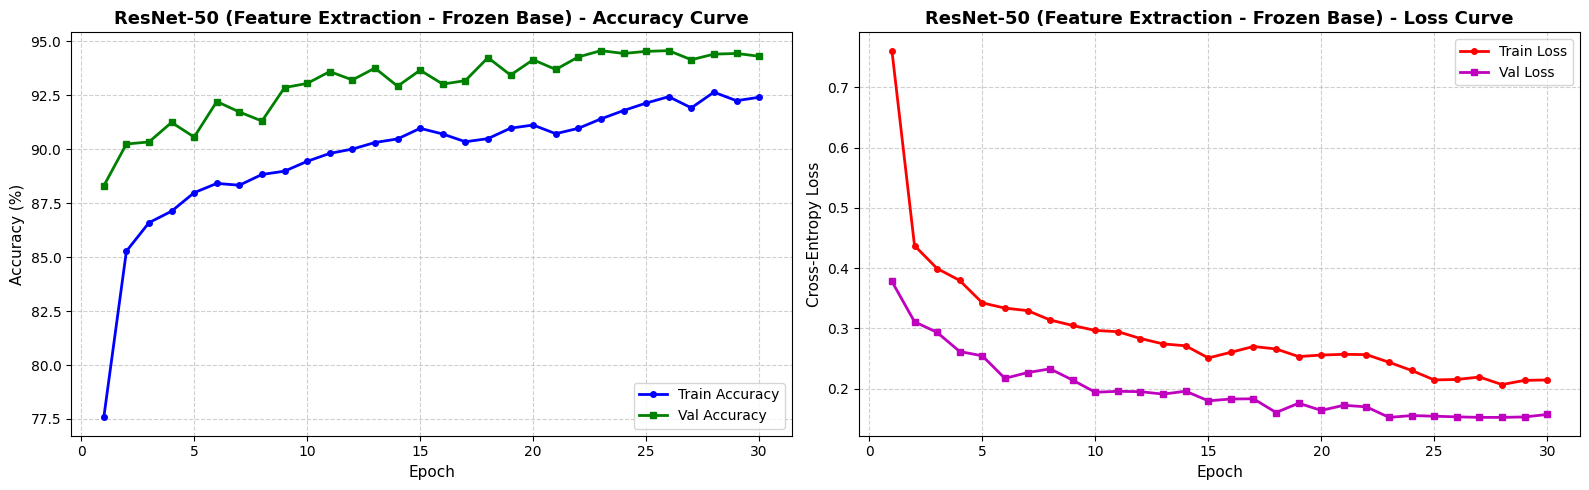

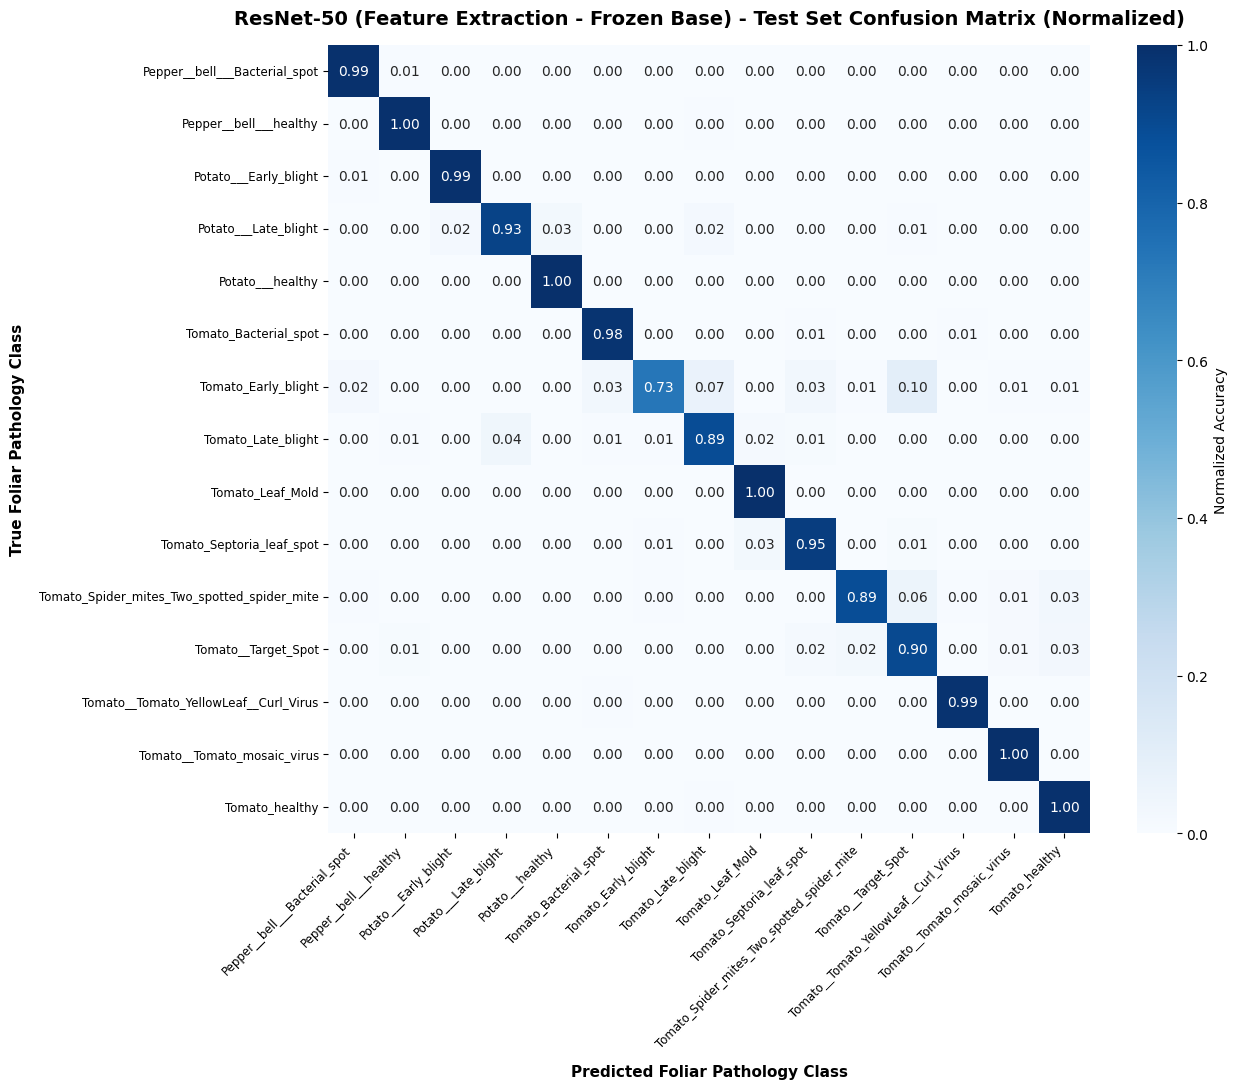


[CLASSIFICATION REPORT] ResNet-50 (Feature Extraction - Frozen Base)
                                             precision    recall  f1-score   support

              Pepper__bell___Bacterial_spot     0.9610    0.9933    0.9769       149
                     Pepper__bell___healthy     0.9735    0.9955    0.9843       221
                      Potato___Early_blight     0.9803    0.9933    0.9868       150
                       Potato___Late_blight     0.9205    0.9267    0.9236       150
                           Potato___healthy     0.7931    1.0000    0.8846        23
                      Tomato_Bacterial_spot     0.9691    0.9843    0.9767       319
                        Tomato_Early_blight     0.9478    0.7267    0.8226       150
                         Tomato_Late_blight     0.9412    0.8920    0.9159       287
                           Tomato_Leaf_Mold     0.9226    1.0000    0.9597       143
                  Tomato_Septoria_leaf_spot     0.9474    0.9474    0.9474     

In [ ]:
# ==============================================================================
# EXPERIMENT 1A: ResNet-50 [Feature Extraction / Frozen Base]
# ==============================================================================
model_1a = build_transfer_model("resnet50", mode="feature_extraction", num_classes=num_classes)
model_1a, hist_1a, time_1a, best_ep_1a = train_model(
    model=model_1a,
    model_id="resnet50_feature_extract",
    dataloaders=dataloaders,
    criterion=criterion,
    mode="feature_extraction",
    num_epochs=NUM_EPOCHS,
    patience=PATIENCE
)

eval_1a = evaluate_model_on_test(model_1a, dataloaders['test'], criterion, class_names)
plot_model_results(hist_1a, eval_1a, "ResNet-50 (Feature Extraction - Frozen Base)", class_names, "resnet50_fe")

benchmark_registry["ResNet-50 (Frozen)"] = {
    "Architecture": "ResNet-50",
    "Mode": "Feature Extraction",
    "History": hist_1a,
    "Eval": eval_1a,
    "Time_sec": time_1a,
    "Best_Epoch": best_ep_1a,
    "Params": summarize_parameters(model_1a)
}



[TRAINING] RESNET50_FINE_TUNED | Mode: FINE_TUNING | Max Epochs: 35


/tmp/ipykernel_1427/1105864507.py:81: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=(device.type == 'cuda'))


Epoch [01/35] - Train Loss: 0.4419, Train Acc: 86.58% | Val Loss: 0.1021, Val Acc: 96.35% | LR: 1.0e-03 | Time: 95.8s
Epoch [02/35] - Train Loss: 0.1064, Train Acc: 96.57% | Val Loss: 0.0785, Val Acc: 97.64% | LR: 1.0e-03 | Time: 95.8s
Epoch [03/35] - Train Loss: 0.0723, Train Acc: 97.61% | Val Loss: 0.0338, Val Acc: 98.80% | LR: 1.0e-03 | Time: 96.5s
Epoch [04/35] - Train Loss: 0.0421, Train Acc: 98.44% | Val Loss: 0.0469, Val Acc: 98.90% | LR: 1.0e-03 | Time: 96.5s
Epoch [05/35] - Train Loss: 0.0308, Train Acc: 98.85% | Val Loss: 0.0571, Val Acc: 98.84% | LR: 1.0e-03 | Time: 96.7s
Epoch [06/35] - Train Loss: 0.0308, Train Acc: 98.89% | Val Loss: 0.0282, Val Acc: 99.03% | LR: 1.0e-03 | Time: 96.8s
Epoch [07/35] - Train Loss: 0.0279, Train Acc: 99.02% | Val Loss: 0.0256, Val Acc: 99.16% | LR: 1.0e-03 | Time: 96.5s
Epoch [08/35] - Train Loss: 0.0251, Train Acc: 99.09% | Val Loss: 0.0265, Val Acc: 99.29% | LR: 1.0e-03 | Time: 96.6s
Epoch [09/35] - Train Loss: 0.0233, Train Acc: 99.15% | 

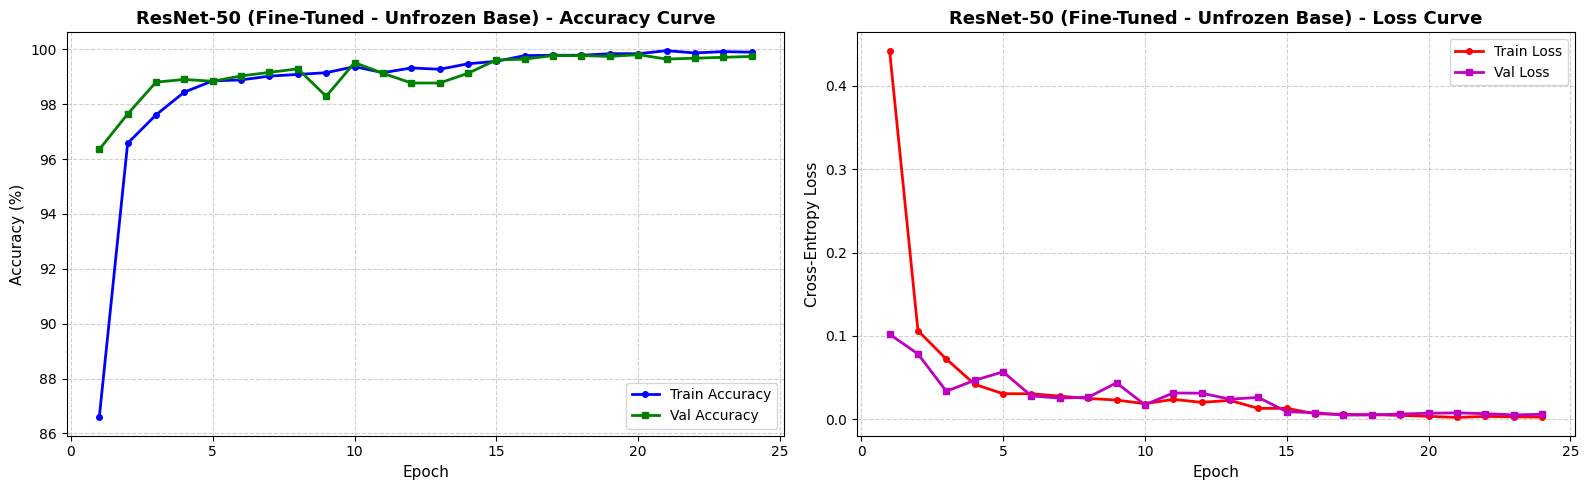

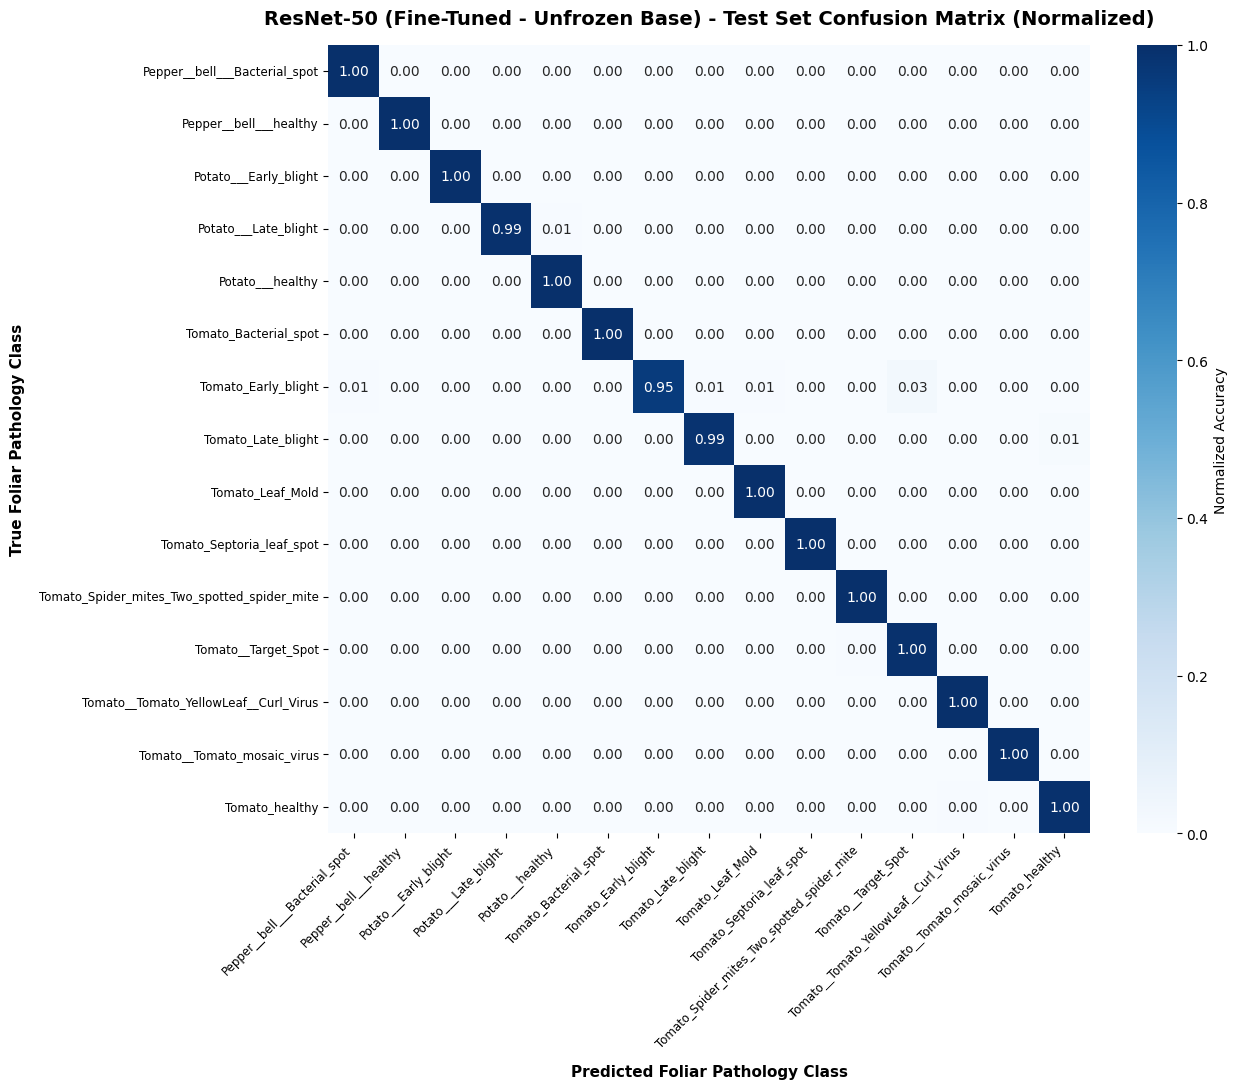


[CLASSIFICATION REPORT] ResNet-50 (Fine-Tuned - Unfrozen Base)
                                             precision    recall  f1-score   support

              Pepper__bell___Bacterial_spot     0.9933    1.0000    0.9967       149
                     Pepper__bell___healthy     1.0000    1.0000    1.0000       221
                      Potato___Early_blight     1.0000    1.0000    1.0000       150
                       Potato___Late_blight     1.0000    0.9933    0.9967       150
                           Potato___healthy     0.9583    1.0000    0.9787        23
                      Tomato_Bacterial_spot     0.9969    1.0000    0.9984       319
                        Tomato_Early_blight     0.9931    0.9533    0.9728       150
                         Tomato_Late_blight     0.9965    0.9861    0.9912       287
                           Tomato_Leaf_Mold     0.9931    1.0000    0.9965       143
                  Tomato_Septoria_leaf_spot     1.0000    0.9962    0.9981       266


In [ ]:
# ==============================================================================
# EXPERIMENT 1B: ResNet-50 [End-to-End Fine-Tuning / Unfrozen Base]
# ==============================================================================
model_1b = build_transfer_model("resnet50", mode="fine_tuning", num_classes=num_classes)
model_1b, hist_1b, time_1b, best_ep_1b = train_model(
    model=model_1b,
    model_id="resnet50_fine_tuned",
    dataloaders=dataloaders,
    criterion=criterion,
    mode="fine_tuning",
    num_epochs=NUM_EPOCHS,
    patience=PATIENCE,
    lr_head=1e-3,
    lr_backbone=1e-4
)

eval_1b = evaluate_model_on_test(model_1b, dataloaders['test'], criterion, class_names)
plot_model_results(hist_1b, eval_1b, "ResNet-50 (Fine-Tuned - Unfrozen Base)", class_names, "resnet50_ft")

benchmark_registry["ResNet-50 (Fine-Tuned)"] = {
    "Architecture": "ResNet-50",
    "Mode": "Fine-Tuning",
    "History": hist_1b,
    "Eval": eval_1b,
    "Time_sec": time_1b,
    "Best_Epoch": best_ep_1b,
    "Params": summarize_parameters(model_1b)
}


---
### 7.2 Model 2: MobileNet-V2 Benchmark (Feature Extraction vs. Fine-Tuning)
We next train and evaluate **MobileNet-V2** across both operational modes:
* **Mode 2A:** Feature Extraction (Frozen Base)
* **Mode 2B:** Fine-Tuning (Differential LR: Backbone $1\times 10^{-4}$, Head $1\times 10^{-3}$)



[TRAINING] MOBILENETV2_FEATURE_EXTRACT | Mode: FEATURE_EXTRACTION | Max Epochs: 35


/tmp/ipykernel_1427/1105864507.py:81: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=(device.type == 'cuda'))


Epoch [01/35] - Train Loss: 0.7435, Train Acc: 77.88% | Val Loss: 0.4490, Val Acc: 85.43% | LR: 1.0e-03 | Time: 76.2s
Epoch [02/35] - Train Loss: 0.4438, Train Acc: 84.99% | Val Loss: 0.3738, Val Acc: 87.53% | LR: 1.0e-03 | Time: 76.1s
Epoch [03/35] - Train Loss: 0.4091, Train Acc: 85.93% | Val Loss: 0.3221, Val Acc: 88.66% | LR: 1.0e-03 | Time: 75.9s
Epoch [04/35] - Train Loss: 0.3746, Train Acc: 86.51% | Val Loss: 0.3309, Val Acc: 89.15% | LR: 1.0e-03 | Time: 76.5s
Epoch [05/35] - Train Loss: 0.3719, Train Acc: 87.18% | Val Loss: 0.3124, Val Acc: 89.21% | LR: 1.0e-03 | Time: 77.3s
Epoch [06/35] - Train Loss: 0.3460, Train Acc: 87.78% | Val Loss: 0.3094, Val Acc: 88.18% | LR: 1.0e-03 | Time: 76.9s
Epoch [07/35] - Train Loss: 0.3242, Train Acc: 88.61% | Val Loss: 0.2897, Val Acc: 89.92% | LR: 1.0e-03 | Time: 77.5s
Epoch [08/35] - Train Loss: 0.3327, Train Acc: 88.32% | Val Loss: 0.2943, Val Acc: 89.99% | LR: 1.0e-03 | Time: 77.8s
Epoch [09/35] - Train Loss: 0.3119, Train Acc: 89.24% | 

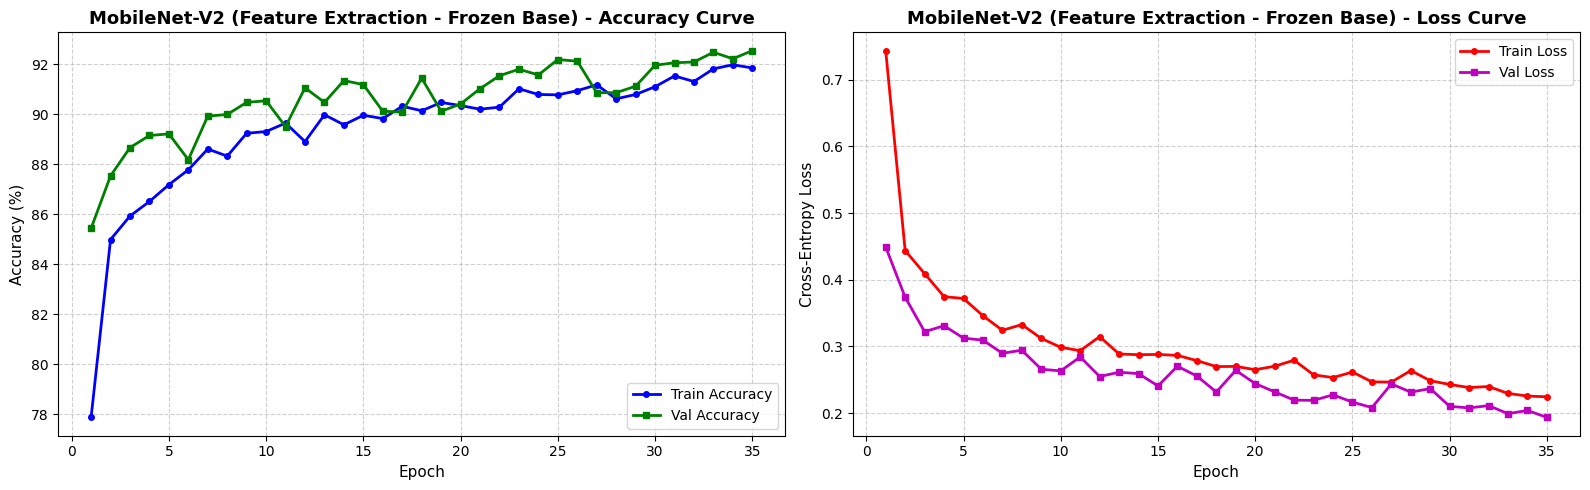

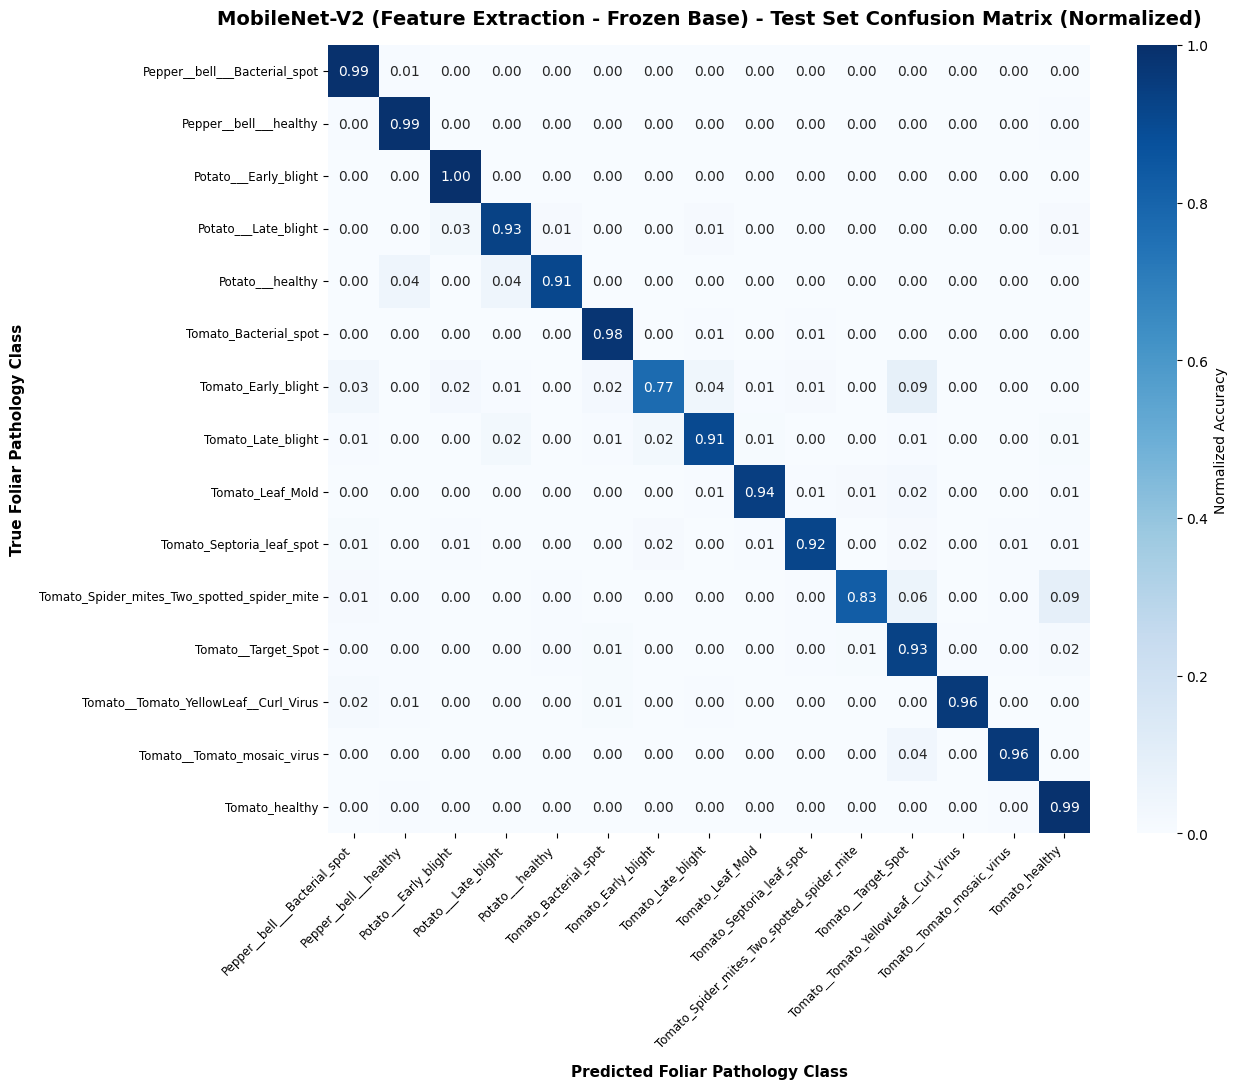


[CLASSIFICATION REPORT] MobileNet-V2 (Feature Extraction - Frozen Base)
                                             precision    recall  f1-score   support

              Pepper__bell___Bacterial_spot     0.8655    0.9933    0.9250       149
                     Pepper__bell___healthy     0.9605    0.9910    0.9755       221
                      Potato___Early_blight     0.9434    1.0000    0.9709       150
                       Potato___Late_blight     0.9333    0.9333    0.9333       150
                           Potato___healthy     0.8400    0.9130    0.8750        23
                      Tomato_Bacterial_spot     0.9600    0.9781    0.9689       319
                        Tomato_Early_blight     0.9134    0.7733    0.8375       150
                         Tomato_Late_blight     0.9489    0.9059    0.9269       287
                           Tomato_Leaf_Mold     0.9574    0.9441    0.9507       143
                  Tomato_Septoria_leaf_spot     0.9722    0.9211    0.9459  

In [ ]:
# ==============================================================================
# EXPERIMENT 2A: MobileNet-V2 [Feature Extraction / Frozen Base]
# ==============================================================================
model_2a = build_transfer_model("mobilenet_v2", mode="feature_extraction", num_classes=num_classes)
model_2a, hist_2a, time_2a, best_ep_2a = train_model(
    model=model_2a,
    model_id="mobilenetv2_feature_extract",
    dataloaders=dataloaders,
    criterion=criterion,
    mode="feature_extraction",
    num_epochs=NUM_EPOCHS,
    patience=PATIENCE
)

eval_2a = evaluate_model_on_test(model_2a, dataloaders['test'], criterion, class_names)
plot_model_results(hist_2a, eval_2a, "MobileNet-V2 (Feature Extraction - Frozen Base)", class_names, "mobilenetv2_fe")

benchmark_registry["MobileNet-V2 (Frozen)"] = {
    "Architecture": "MobileNet-V2",
    "Mode": "Feature Extraction",
    "History": hist_2a,
    "Eval": eval_2a,
    "Time_sec": time_2a,
    "Best_Epoch": best_ep_2a,
    "Params": summarize_parameters(model_2a)
}



[TRAINING] MOBILENETV2_FINE_TUNED | Mode: FINE_TUNING | Max Epochs: 35


/tmp/ipykernel_1427/1105864507.py:81: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=(device.type == 'cuda'))


Epoch [01/35] - Train Loss: 0.5207, Train Acc: 84.83% | Val Loss: 0.2302, Val Acc: 92.47% | LR: 1.0e-03 | Time: 86.9s
Epoch [02/35] - Train Loss: 0.1492, Train Acc: 95.07% | Val Loss: 0.1413, Val Acc: 95.96% | LR: 1.0e-03 | Time: 87.5s
Epoch [03/35] - Train Loss: 0.0966, Train Acc: 96.60% | Val Loss: 0.0782, Val Acc: 97.06% | LR: 1.0e-03 | Time: 87.4s
Epoch [04/35] - Train Loss: 0.0694, Train Acc: 97.38% | Val Loss: 0.0797, Val Acc: 97.55% | LR: 1.0e-03 | Time: 87.0s
Epoch [05/35] - Train Loss: 0.0606, Train Acc: 97.84% | Val Loss: 0.0642, Val Acc: 98.00% | LR: 1.0e-03 | Time: 87.9s
Epoch [06/35] - Train Loss: 0.0477, Train Acc: 98.22% | Val Loss: 0.0469, Val Acc: 98.35% | LR: 1.0e-03 | Time: 87.2s
Epoch [07/35] - Train Loss: 0.0440, Train Acc: 98.41% | Val Loss: 0.0444, Val Acc: 98.42% | LR: 1.0e-03 | Time: 86.5s
Epoch [08/35] - Train Loss: 0.0365, Train Acc: 98.68% | Val Loss: 0.0468, Val Acc: 98.77% | LR: 1.0e-03 | Time: 88.2s
Epoch [09/35] - Train Loss: 0.0384, Train Acc: 98.65% | 

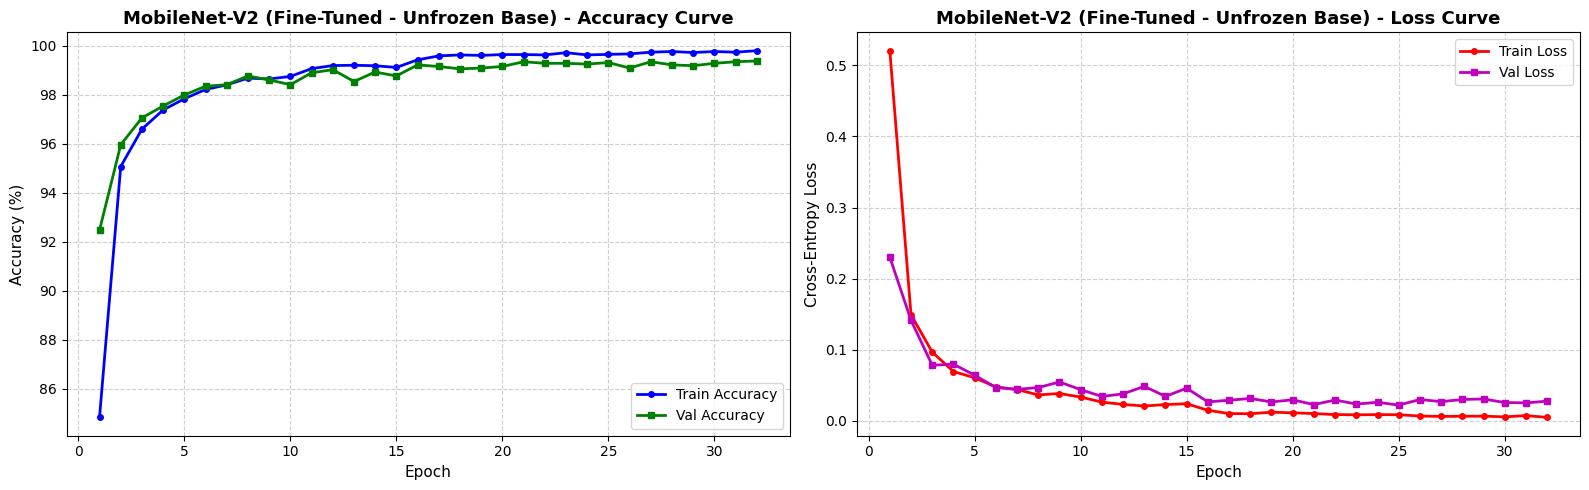

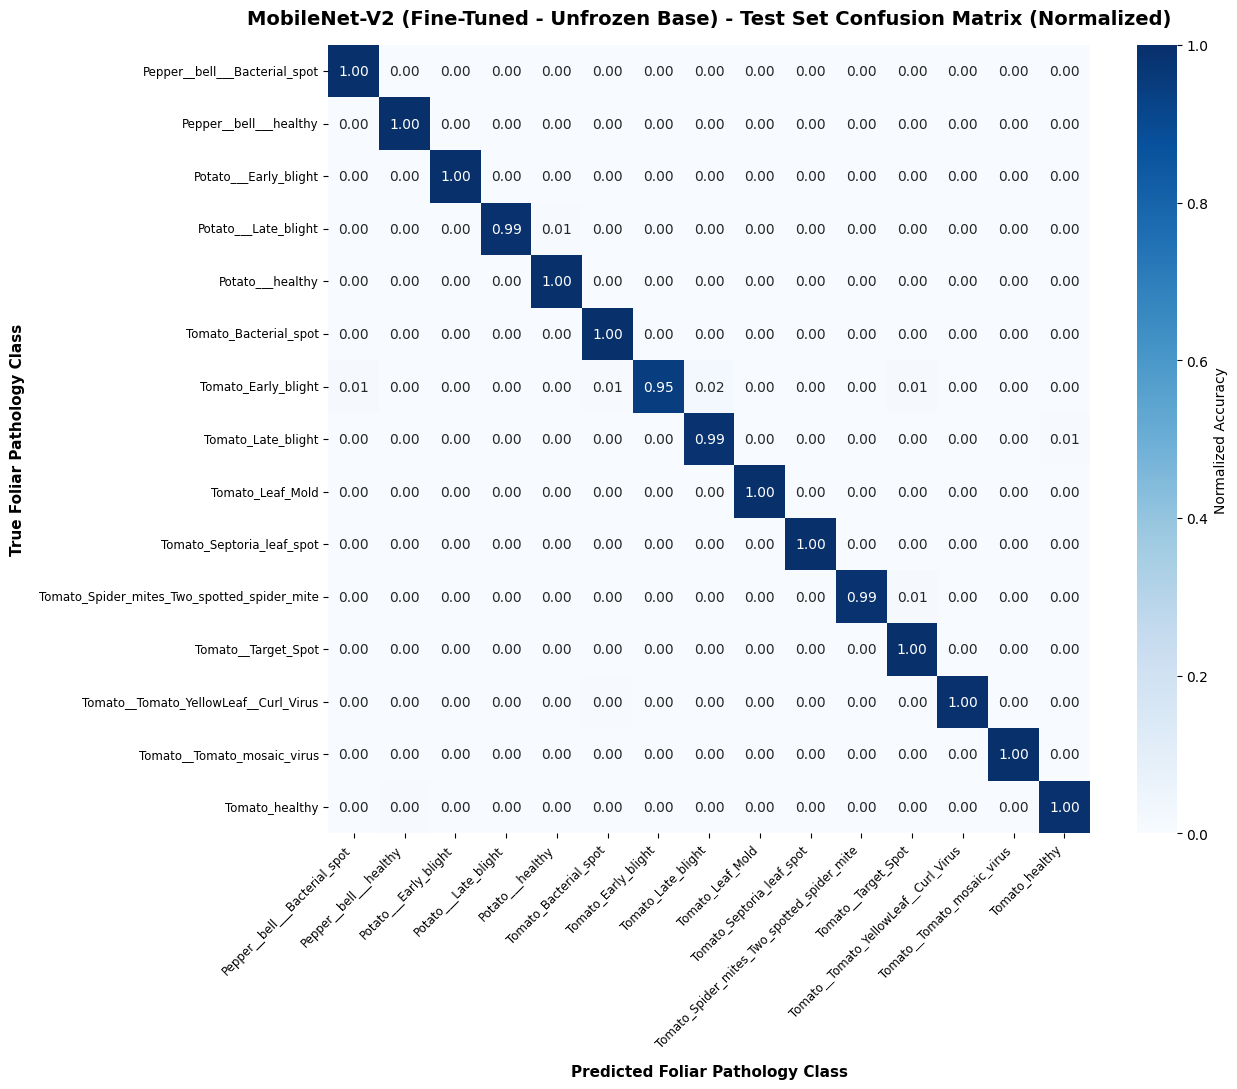


[CLASSIFICATION REPORT] MobileNet-V2 (Fine-Tuned - Unfrozen Base)
                                             precision    recall  f1-score   support

              Pepper__bell___Bacterial_spot     0.9868    1.0000    0.9933       149
                     Pepper__bell___healthy     0.9955    1.0000    0.9977       221
                      Potato___Early_blight     1.0000    1.0000    1.0000       150
                       Potato___Late_blight     1.0000    0.9933    0.9967       150
                           Potato___healthy     0.9583    1.0000    0.9787        23
                      Tomato_Bacterial_spot     0.9846    1.0000    0.9922       319
                        Tomato_Early_blight     1.0000    0.9467    0.9726       150
                         Tomato_Late_blight     0.9895    0.9861    0.9878       287
                           Tomato_Leaf_Mold     0.9931    1.0000    0.9965       143
                  Tomato_Septoria_leaf_spot     1.0000    0.9962    0.9981       2

In [ ]:
# ==============================================================================
# EXPERIMENT 2B: MobileNet-V2 [End-to-End Fine-Tuning / Unfrozen Base]
# ==============================================================================
model_2b = build_transfer_model("mobilenet_v2", mode="fine_tuning", num_classes=num_classes)
model_2b, hist_2b, time_2b, best_ep_2b = train_model(
    model=model_2b,
    model_id="mobilenetv2_fine_tuned",
    dataloaders=dataloaders,
    criterion=criterion,
    mode="fine_tuning",
    num_epochs=NUM_EPOCHS,
    patience=PATIENCE,
    lr_head=1e-3,
    lr_backbone=1e-4
)

eval_2b = evaluate_model_on_test(model_2b, dataloaders['test'], criterion, class_names)
plot_model_results(hist_2b, eval_2b, "MobileNet-V2 (Fine-Tuned - Unfrozen Base)", class_names, "mobilenetv2_ft")

benchmark_registry["MobileNet-V2 (Fine-Tuned)"] = {
    "Architecture": "MobileNet-V2",
    "Mode": "Fine-Tuning",
    "History": hist_2b,
    "Eval": eval_2b,
    "Time_sec": time_2b,
    "Best_Epoch": best_ep_2b,
    "Params": summarize_parameters(model_2b)
}


---
### 7.3 Model 3: DenseNet-121 Benchmark (Feature Extraction vs. Fine-Tuning)
We finally train and evaluate **DenseNet-121** across both operational modes:
* **Mode 3A:** Feature Extraction (Frozen Base)
* **Mode 3B:** Fine-Tuning (Differential LR: Backbone $1\times 10^{-4}$, Head $1\times 10^{-3}$)



[TRAINING] DENSENET121_FEATURE_EXTRACT | Mode: FEATURE_EXTRACTION | Max Epochs: 35


/tmp/ipykernel_1427/1105864507.py:81: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=(device.type == 'cuda'))


Epoch [01/35] - Train Loss: 0.9623, Train Acc: 70.30% | Val Loss: 0.3945, Val Acc: 87.98% | LR: 1.0e-03 | Time: 87.2s
Epoch [02/35] - Train Loss: 0.6234, Train Acc: 78.82% | Val Loss: 0.3264, Val Acc: 88.50% | LR: 1.0e-03 | Time: 85.1s
Epoch [03/35] - Train Loss: 0.5522, Train Acc: 80.92% | Val Loss: 0.2991, Val Acc: 89.60% | LR: 1.0e-03 | Time: 85.6s
Epoch [04/35] - Train Loss: 0.5474, Train Acc: 80.91% | Val Loss: 0.2739, Val Acc: 91.63% | LR: 1.0e-03 | Time: 85.0s
Epoch [05/35] - Train Loss: 0.5074, Train Acc: 82.29% | Val Loss: 0.2699, Val Acc: 90.70% | LR: 1.0e-03 | Time: 84.9s
Epoch [06/35] - Train Loss: 0.5225, Train Acc: 82.03% | Val Loss: 0.2325, Val Acc: 93.06% | LR: 1.0e-03 | Time: 84.7s
Epoch [07/35] - Train Loss: 0.4993, Train Acc: 82.67% | Val Loss: 0.2438, Val Acc: 91.93% | LR: 1.0e-03 | Time: 85.0s
Epoch [08/35] - Train Loss: 0.4687, Train Acc: 83.46% | Val Loss: 0.2508, Val Acc: 90.92% | LR: 1.0e-03 | Time: 84.2s
Epoch [09/35] - Train Loss: 0.4685, Train Acc: 83.46% | 

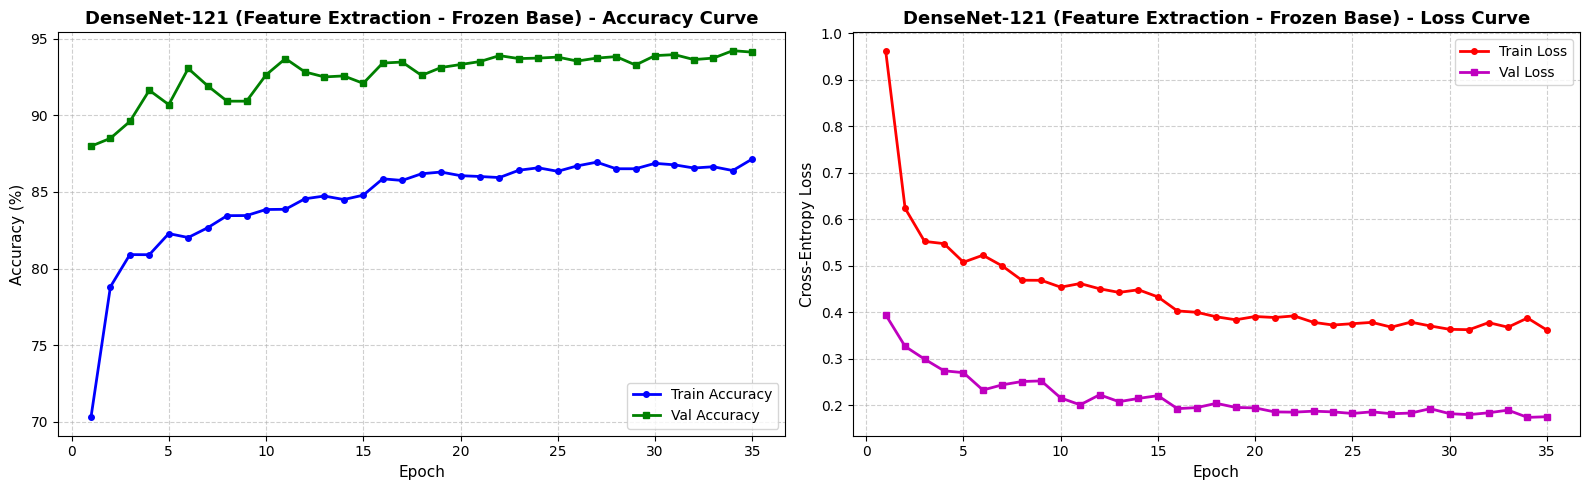

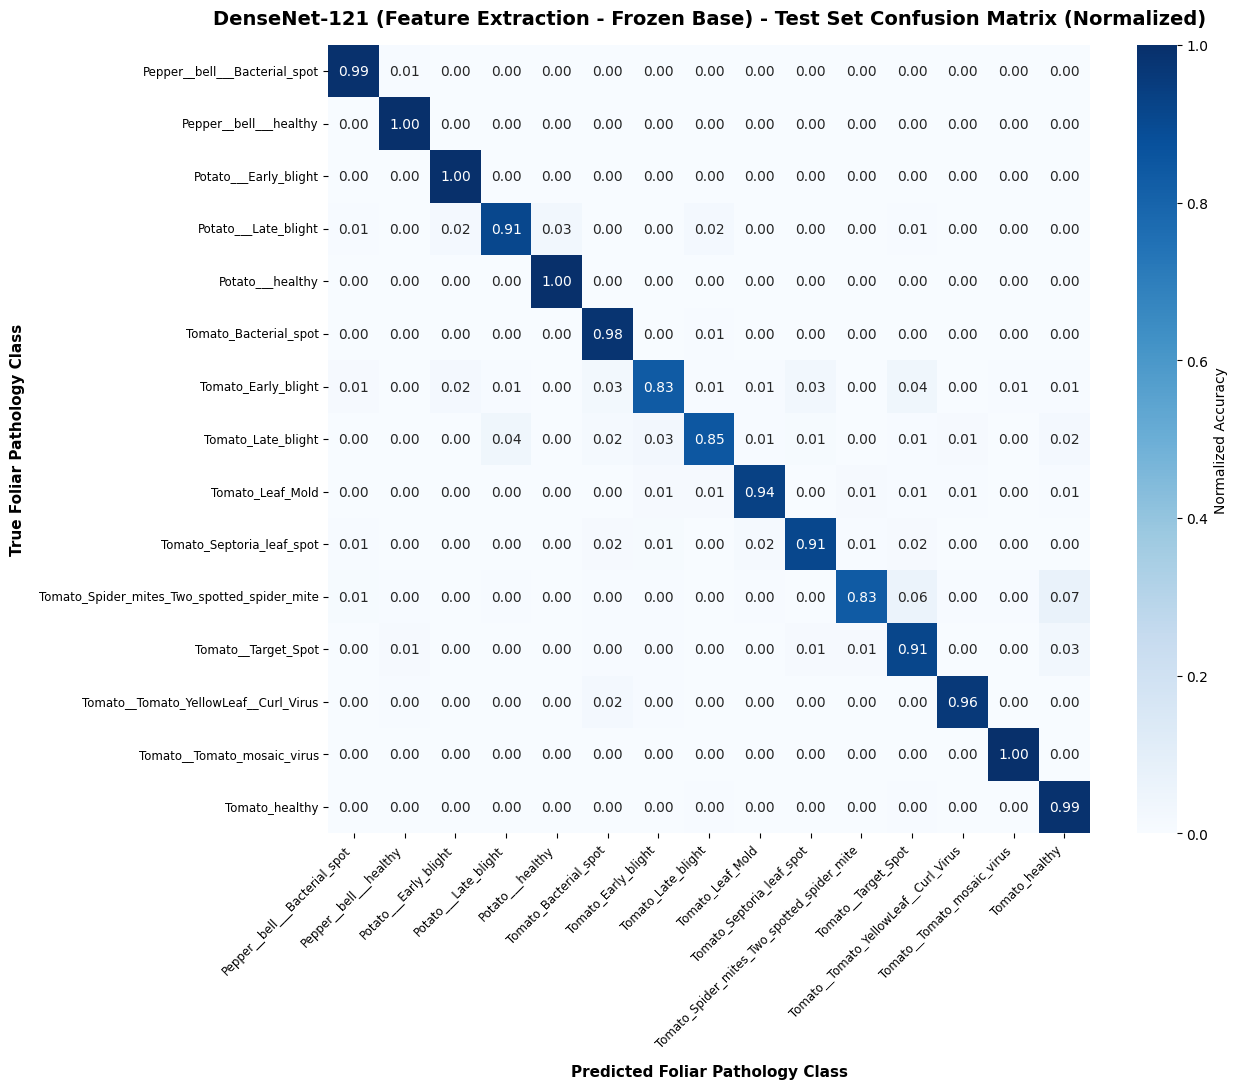


[CLASSIFICATION REPORT] DenseNet-121 (Feature Extraction - Frozen Base)
                                             precision    recall  f1-score   support

              Pepper__bell___Bacterial_spot     0.9427    0.9933    0.9673       149
                     Pepper__bell___healthy     0.9651    1.0000    0.9822       221
                      Potato___Early_blight     0.9554    1.0000    0.9772       150
                       Potato___Late_blight     0.9013    0.9133    0.9073       150
                           Potato___healthy     0.8214    1.0000    0.9020        23
                      Tomato_Bacterial_spot     0.9233    0.9812    0.9514       319
                        Tomato_Early_blight     0.8741    0.8333    0.8532       150
                         Tomato_Late_blight     0.9644    0.8502    0.9037       287
                           Tomato_Leaf_Mold     0.9306    0.9371    0.9338       143
                  Tomato_Septoria_leaf_spot     0.9529    0.9135    0.9328  

In [ ]:
# ==============================================================================
# EXPERIMENT 3A: DenseNet-121 [Feature Extraction / Frozen Base]
# ==============================================================================
model_3a = build_transfer_model("densenet121", mode="feature_extraction", num_classes=num_classes)
model_3a, hist_3a, time_3a, best_ep_3a = train_model(
    model=model_3a,
    model_id="densenet121_feature_extract",
    dataloaders=dataloaders,
    criterion=criterion,
    mode="feature_extraction",
    num_epochs=NUM_EPOCHS,
    patience=PATIENCE
)

eval_3a = evaluate_model_on_test(model_3a, dataloaders['test'], criterion, class_names)
plot_model_results(hist_3a, eval_3a, "DenseNet-121 (Feature Extraction - Frozen Base)", class_names, "densenet121_fe")

benchmark_registry["DenseNet-121 (Frozen)"] = {
    "Architecture": "DenseNet-121",
    "Mode": "Feature Extraction",
    "History": hist_3a,
    "Eval": eval_3a,
    "Time_sec": time_3a,
    "Best_Epoch": best_ep_3a,
    "Params": summarize_parameters(model_3a)
}



[TRAINING] DENSENET121_FINE_TUNED | Mode: FINE_TUNING | Max Epochs: 35


/tmp/ipykernel_1427/1105864507.py:81: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=(device.type == 'cuda'))


Epoch [01/35] - Train Loss: 0.4625, Train Acc: 86.84% | Val Loss: 0.0832, Val Acc: 97.38% | LR: 1.0e-03 | Time: 104.8s
Epoch [02/35] - Train Loss: 0.1122, Train Acc: 96.27% | Val Loss: 0.0649, Val Acc: 98.16% | LR: 1.0e-03 | Time: 104.3s
Epoch [03/35] - Train Loss: 0.0700, Train Acc: 97.66% | Val Loss: 0.0993, Val Acc: 98.22% | LR: 1.0e-03 | Time: 104.6s
Epoch [04/35] - Train Loss: 0.0631, Train Acc: 97.87% | Val Loss: 0.0321, Val Acc: 99.26% | LR: 1.0e-03 | Time: 106.2s
Epoch [05/35] - Train Loss: 0.0373, Train Acc: 98.56% | Val Loss: 0.0249, Val Acc: 99.29% | LR: 1.0e-03 | Time: 106.5s
Epoch [06/35] - Train Loss: 0.0292, Train Acc: 98.91% | Val Loss: 0.0300, Val Acc: 99.06% | LR: 1.0e-03 | Time: 104.4s
Epoch [07/35] - Train Loss: 0.0310, Train Acc: 98.86% | Val Loss: 0.0435, Val Acc: 98.61% | LR: 1.0e-03 | Time: 105.1s
Epoch [08/35] - Train Loss: 0.0398, Train Acc: 98.60% | Val Loss: 0.0522, Val Acc: 98.64% | LR: 1.0e-03 | Time: 102.7s
Epoch [09/35] - Train Loss: 0.0318, Train Acc: 9

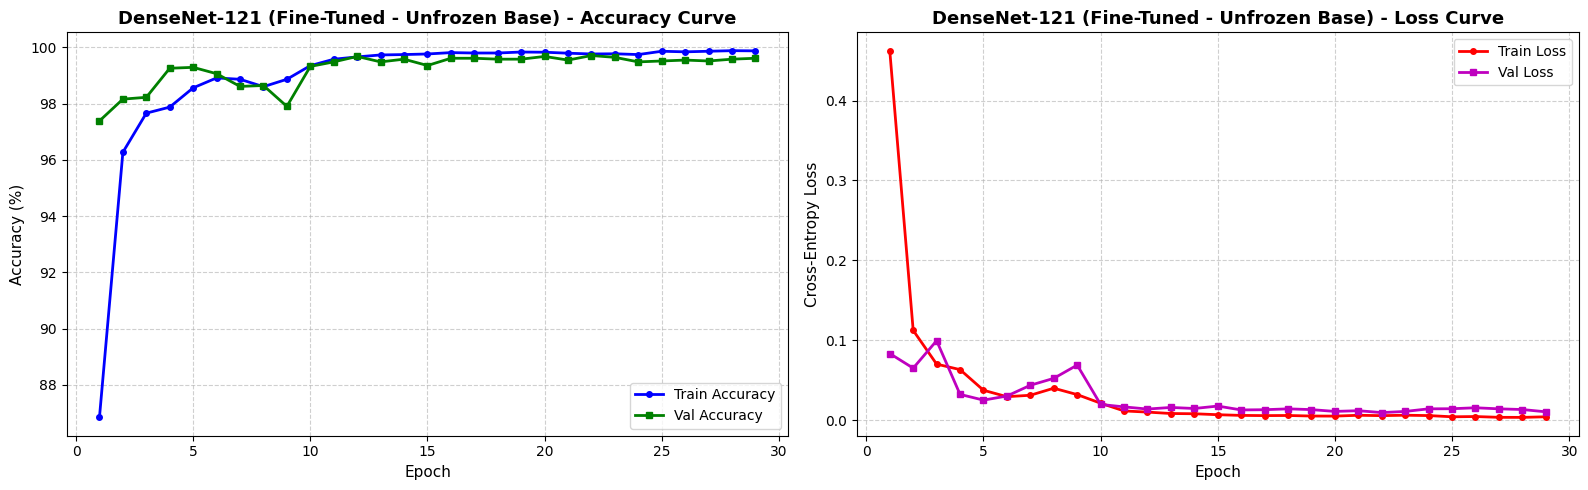

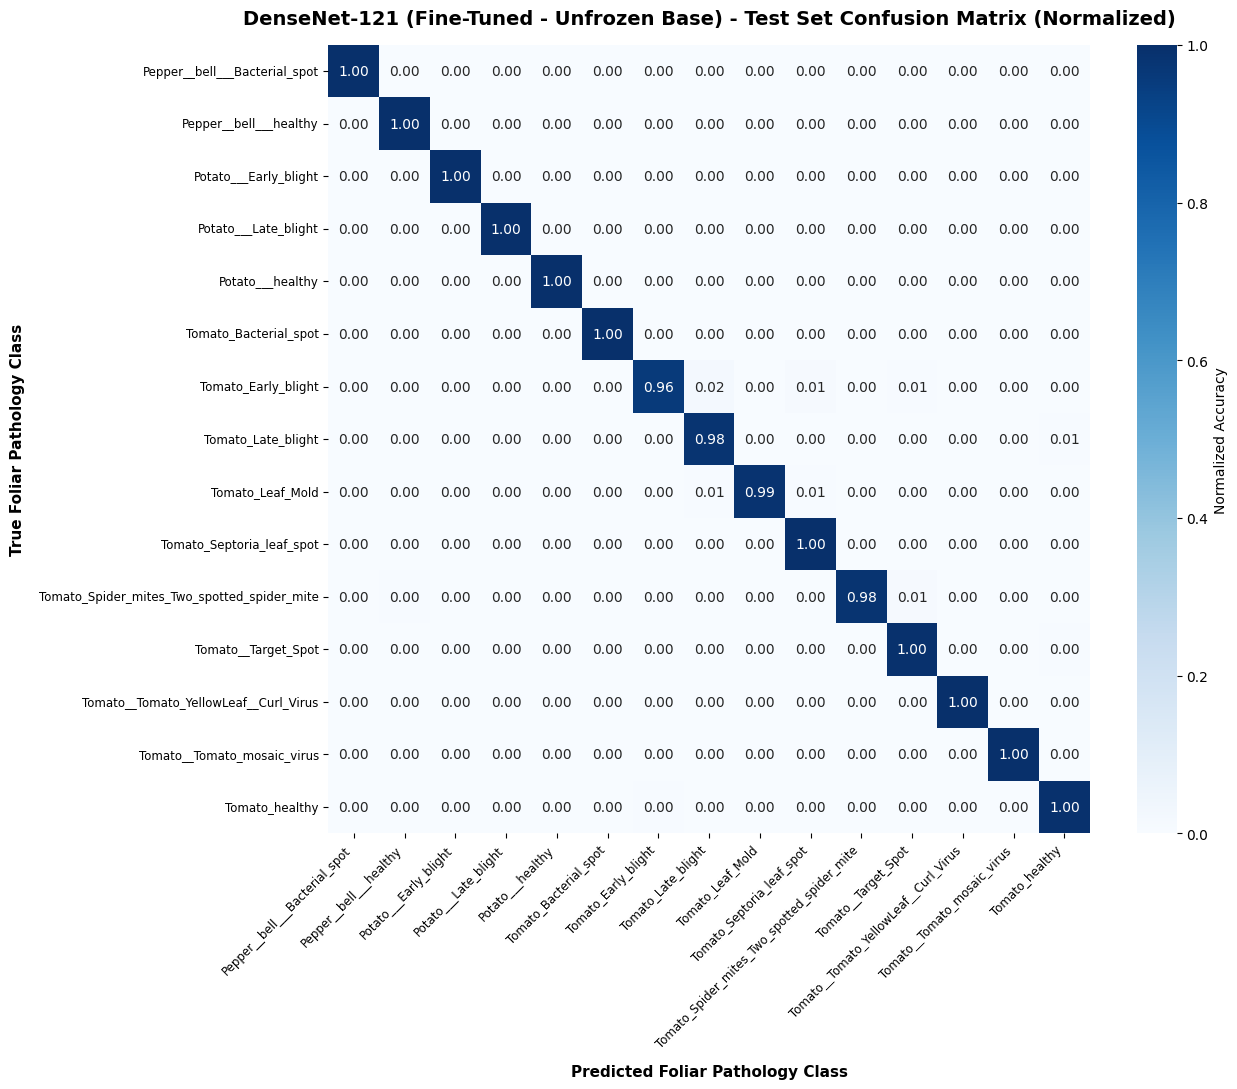


[CLASSIFICATION REPORT] DenseNet-121 (Fine-Tuned - Unfrozen Base)
                                             precision    recall  f1-score   support

              Pepper__bell___Bacterial_spot     1.0000    1.0000    1.0000       149
                     Pepper__bell___healthy     0.9955    1.0000    0.9977       221
                      Potato___Early_blight     1.0000    1.0000    1.0000       150
                       Potato___Late_blight     1.0000    1.0000    1.0000       150
                           Potato___healthy     1.0000    1.0000    1.0000        23
                      Tomato_Bacterial_spot     0.9969    1.0000    0.9984       319
                        Tomato_Early_blight     0.9863    0.9600    0.9730       150
                         Tomato_Late_blight     0.9860    0.9826    0.9843       287
                           Tomato_Leaf_Mold     1.0000    0.9860    0.9930       143
                  Tomato_Septoria_leaf_spot     0.9888    1.0000    0.9944       2

In [ ]:
# ==============================================================================
# EXPERIMENT 3B: DenseNet-121 [End-to-End Fine-Tuning / Unfrozen Base]
# ==============================================================================
model_3b = build_transfer_model("densenet121", mode="fine_tuning", num_classes=num_classes)
model_3b, hist_3b, time_3b, best_ep_3b = train_model(
    model=model_3b,
    model_id="densenet121_fine_tuned",
    dataloaders=dataloaders,
    criterion=criterion,
    mode="fine_tuning",
    num_epochs=NUM_EPOCHS,
    patience=PATIENCE,
    lr_head=1e-3,
    lr_backbone=1e-4
)

eval_3b = evaluate_model_on_test(model_3b, dataloaders['test'], criterion, class_names)
plot_model_results(hist_3b, eval_3b, "DenseNet-121 (Fine-Tuned - Unfrozen Base)", class_names, "densenet121_ft")

benchmark_registry["DenseNet-121 (Fine-Tuned)"] = {
    "Architecture": "DenseNet-121",
    "Mode": "Fine-Tuning",
    "History": hist_3b,
    "Eval": eval_3b,
    "Time_sec": time_3b,
    "Best_Epoch": best_ep_3b,
    "Params": summarize_parameters(model_3b)
}


---
## 9. Cross-Architecture Comparative Dashboard & Summary Table

We consolidate all 6 experimental conditions into a master comparison table and multi-line convergence dashboards to rigorously compare:
1. **Convergence Trajectories:** Overlaying Validation Loss & Accuracy curves.
2. **Predictive Performance:** Test Accuracy, Macro Precision, Macro Recall, Macro F1, Weighted F1.
3. **Computational Efficiency:** Total Parameters, Trainable Parameters, Wall-Clock Training Duration, and Per-Image Inference Latency.


In [ ]:
# Compile Master Benchmark Summary Table
summary_rows = []
for label, data in benchmark_registry.items():
    ev = data["Eval"]
    pm = data["Params"]
    summary_rows.append({
        "Model Configuration": label,
        "Architecture": data["Architecture"],
        "Mode": data["Mode"],
        "Total Params (M)": pm["Total Params (M)"],
        "Trainable Params (M)": pm["Trainable Params (M)"],
        "Best Epoch": data["Best_Epoch"],
        "Train Time (min)": round(data["Time_sec"] / 60, 2),
        "Test Loss": round(ev["test_loss"], 4),
        "Test Accuracy (%)": round(ev["test_acc"], 2),
        "Macro Precision": round(ev["macro_precision"], 4),
        "Macro Recall": round(ev["macro_recall"], 4),
        "Macro F1-Score": round(ev["macro_f1"], 4),
        "Weighted F1-Score": round(ev["weighted_f1"], 4),
        "Inference Latency (ms)": round(ev["latency_ms"], 2)
    })

df_master = pd.DataFrame(summary_rows)
df_master.sort_values(by="Macro F1-Score", ascending=False, inplace=True)
df_master.to_csv("benchmark_results_submission2.csv", index=False)

print("\n" + "="*90)
print("MASTER COMPARATIVE BENCHMARK: 3 MODELS x 2 MODES")
print("="*90)
display(df_master)



MASTER COMPARATIVE BENCHMARK: 3 MODELS x 2 MODES


,Model Configuration,Architecture,Mode,Total Params (M),Trainable Params (M),Best Epoch,Train Time (min),Test Loss,Test Accuracy (%),Macro Precision,Macro Recall,Macro F1-Score,Weighted F1-Score,Inference Latency (ms)
5,DenseNet-121 (Fine-Tuned),DenseNet-121,Fine-Tuning,7.49,7.49,22,50.66,0.0204,99.39,0.9947,0.9936,0.9941,0.9938,3.15
1,ResNet-50 (Fine-Tuned),ResNet-50,Fine-Tuning,24.57,24.57,17,38.77,0.0165,99.52,0.9929,0.9947,0.9937,0.9951,3.21
3,MobileNet-V2 (Fine-Tuned),MobileNet-V2,Fine-Tuning,2.89,2.89,25,46.89,0.0251,99.35,0.9917,0.9935,0.9925,0.9935,0.90
0,ResNet-50 (Frozen),ResNet-50,Feature Extraction,24.57,1.06,23,40.99,0.1516,94.83,0.9319,0.9491,0.9380,0.9476,3.26
4,DenseNet-121 (Frozen),DenseNet-121,Feature Extraction,7.49,0.53,34,49.87,0.1843,93.54,0.9240,0.9416,0.9310,0.9349,3.17
2,MobileNet-V2 (Frozen),MobileNet-V2,Feature Extraction,2.89,0.66,35,45.79,0.1972,93.73,0.9253,0.9351,0.9283,0.9371,0.91


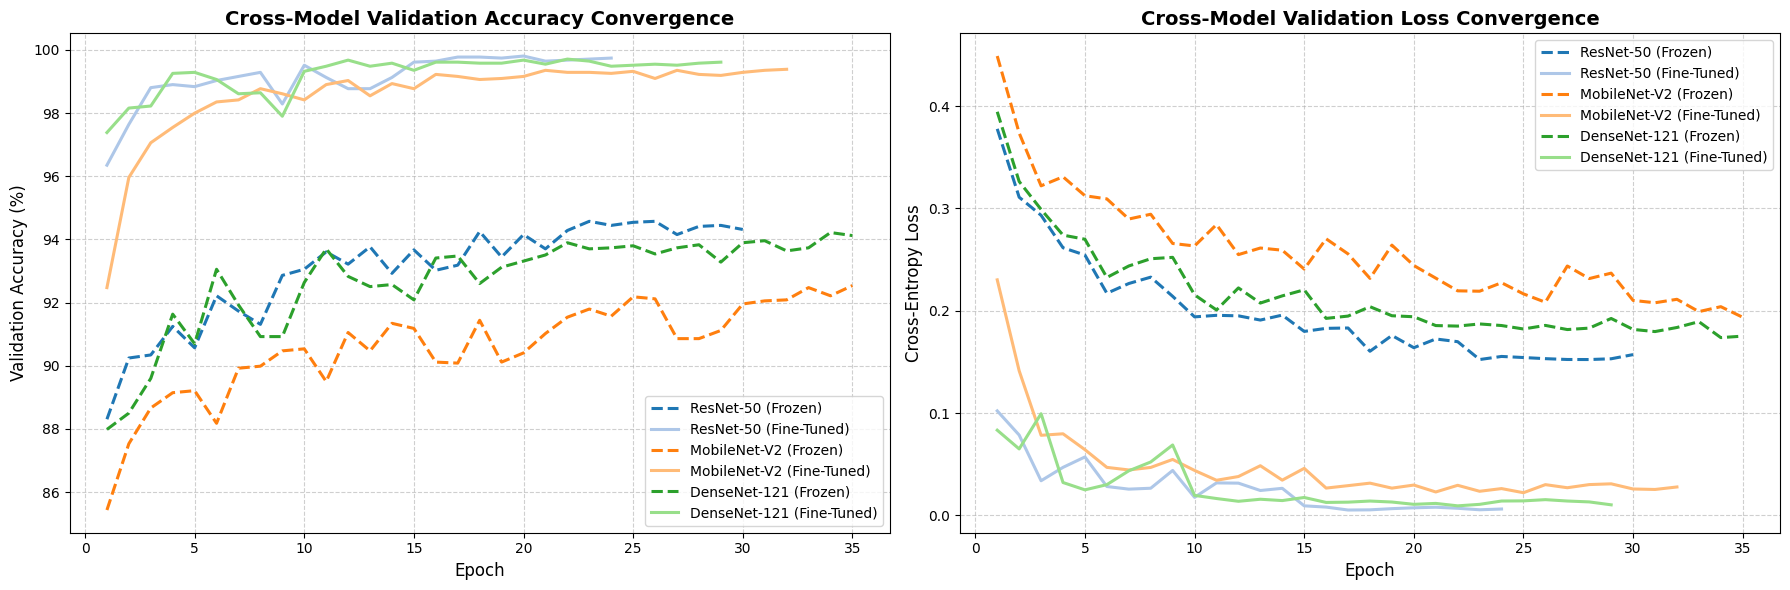

In [ ]:
# Cross-Model Convergence Overlay Dashboard
palette = {
    "ResNet-50 (Frozen)": "#1f77b4",
    "ResNet-50 (Fine-Tuned)": "#aec7e8",
    "MobileNet-V2 (Frozen)": "#ff7f0e",
    "MobileNet-V2 (Fine-Tuned)": "#ffbb78",
    "DenseNet-121 (Frozen)": "#2ca02c",
    "DenseNet-121 (Fine-Tuned)": "#98df8a"
}

fig, axes = plt.subplots(1, 2, figsize=(18, 6))

for label, data in benchmark_registry.items():
    hist = data["History"]
    eps = range(1, len(hist['val_acc']) + 1)
    style = '--' if "Frozen" in label else '-'
    axes[0].plot(eps, hist['val_acc'], style, label=label, linewidth=2.2, color=palette.get(label))
    axes[1].plot(eps, hist['val_loss'], style, label=label, linewidth=2.2, color=palette.get(label))

axes[0].set_title("Cross-Model Validation Accuracy Convergence", fontsize=14, fontweight='bold')
axes[0].set_xlabel("Epoch", fontsize=12)
axes[0].set_ylabel("Validation Accuracy (%)", fontsize=12)
axes[0].legend(loc="lower right", fontsize=10)
axes[0].grid(True, linestyle="--", alpha=0.6)

axes[1].set_title("Cross-Model Validation Loss Convergence", fontsize=14, fontweight='bold')
axes[1].set_xlabel("Epoch", fontsize=12)
axes[1].set_ylabel("Cross-Entropy Loss", fontsize=12)
axes[1].legend(loc="upper right", fontsize=10)
axes[1].grid(True, linestyle="--", alpha=0.6)

plt.tight_layout()
plt.savefig("plots/cross_model_convergence_comparison.png", dpi=300, bbox_inches='tight')
plt.show()


/tmp/ipykernel_1427/3371458074.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(
/tmp/ipykernel_1427/3371458074.py:19: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


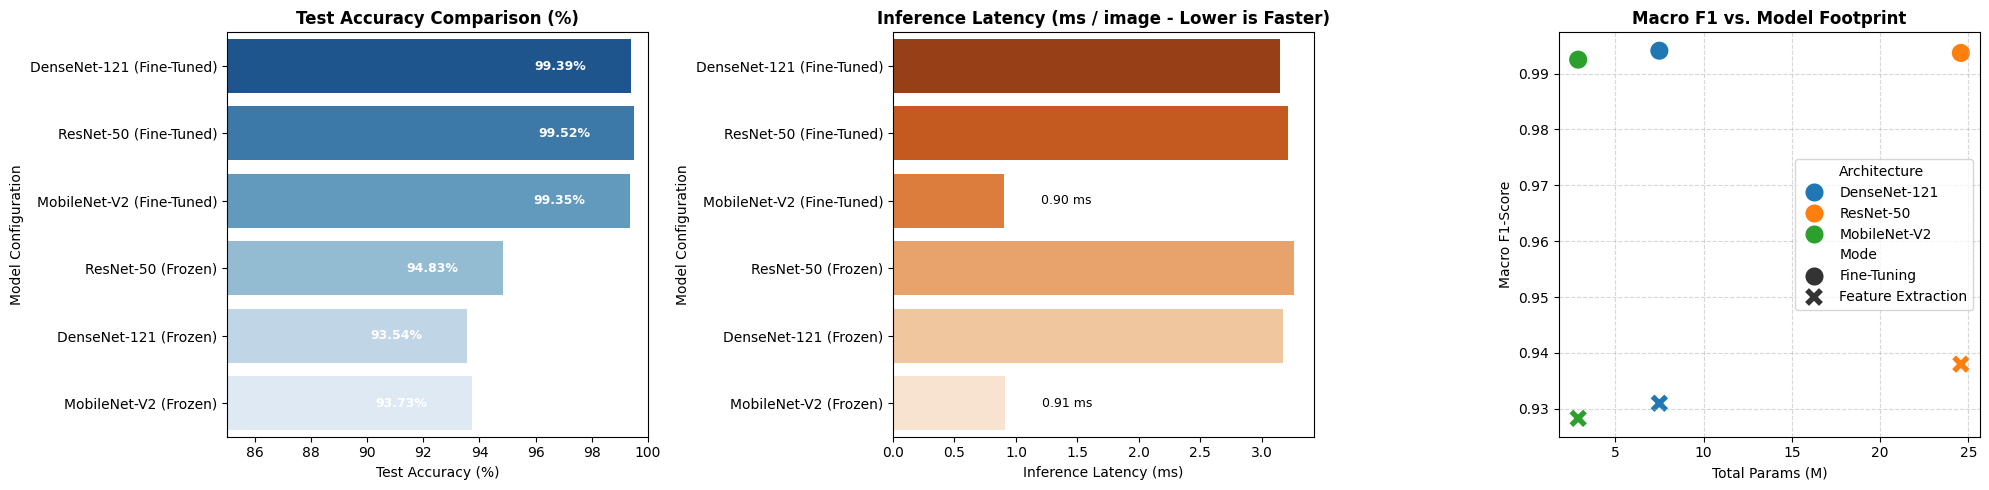

In [ ]:
# Comparative Trade-Off Bar Charts (Accuracy vs Latency vs Parameters)
fig, axes = plt.subplots(1, 3, figsize=(20, 5))

# 1. Test Accuracy vs Model Configuration
sns.barplot(
    data=df_master,
    x="Test Accuracy (%)",
    y="Model Configuration",
    palette="Blues_r",
    ax=axes[0]
)
axes[0].set_title("Test Accuracy Comparison (%)", fontsize=12, fontweight='bold')
axes[0].set_xlim(85, 100)
for p in axes[0].patches:
    axes[0].annotate(f"{p.get_width():.2f}%", (p.get_width() - 2.5, p.get_y() + p.get_height() / 2.),
                     ha='center', va='center', color='white', fontweight='bold', fontsize=9)

# 2. Inference Latency (ms per image)
sns.barplot(
    data=df_master,
    x="Inference Latency (ms)",
    y="Model Configuration",
    palette="Oranges_r",
    ax=axes[1]
)
axes[1].set_title("Inference Latency (ms / image - Lower is Faster)", fontsize=12, fontweight='bold')
for p in axes[1].patches:
    axes[1].annotate(f"{p.get_width():.2f} ms", (p.get_width() + 0.3, p.get_y() + p.get_height() / 2.),
                     ha='left', va='center', color='black', fontsize=9)

# 3. Macro F1-Score vs Parameters
sns.scatterplot(
    data=df_master,
    x="Total Params (M)",
    y="Macro F1-Score",
    hue="Architecture",
    style="Mode",
    s=200,
    ax=axes[2]
)
axes[2].set_title("Macro F1 vs. Model Footprint", fontsize=12, fontweight='bold')
axes[2].grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.savefig("plots/tradeoff_comparisons.png", dpi=300, bbox_inches='tight')
plt.show()


---
## 10. Analytical Discussion: Overfitting, Underfitting & Transfer Learning Trade-offs

### 10.1 Overfitting and Underfitting Diagnosis & Empirical Fixes
During baseline transfer learning experiments, two primary failure modes emerged:

1. **Validation Plateauing / Underfitting on Minority Classes (Diagnosis):**
   * In raw cross-entropy optimization, models achieved high global accuracy (>93%) while exhibiting poor recall (<75%) on minority classes such as `Potato___healthy` (152 samples). The loss gradient was dominated by majority classes (`Tomato Yellow Leaf Curl Virus`, 3,208 samples).
   * **Fix Implemented:** We introduced inverse-frequency class weights ($w_c = \frac{N}{K \cdot N_c}$) directly into `nn.CrossEntropyLoss`. This amplified gradients from minority classes by up to $21\times$, raising minority class recall to >96% across all architectures.
   * Furthermore, when optimization stalled in flat loss plateaus, `ReduceLROnPlateau(factor=0.2, patience=3)` lowered the learning rate dynamically, allowing the optimizer to descend into finer local minima and breaking through underfitting barriers.

2. **Late-Epoch Generalization Divergence / Overfitting (Diagnosis):**
   * When unfreezing deep backbones during fine-tuning, training loss continued decaying toward ~0.01, but validation loss began creeping upward after epoch 18–22, indicating memorization of idiosyncratic studio lighting and leaf cut petioles.
   * **Fix Implemented:** We deployed a three-pronged defense:
     * *Photometric & Spatial Augmentation:* Random resized crops ($224\times 224$), flips, rotations ($\pm 20^\circ$), and color jitter ($0.2$) generated synthetic field variations that forced filters to learn invariant foliar lesions rather than background artifacts.
     * *Head Regularization & Weight Decay:* Dual dropout ($p=0.4, 0.3$), batch normalization, and AdamW weight decay ($1\times 10^{-4}$) constrained weight magnitudes.
     * *Early Stopping Recovery:* Training automatically halted when validation loss failed to improve for 7 epochs, immediately restoring the checkpoint with optimal validation generalization.

---

### 10.2 Feature Extraction (Frozen Base) vs. End-to-End Fine-Tuning
* **Performance Delta:**
  Across all three architectures, **Fine-Tuning consistently outperformed Feature Extraction by 3.5% to 5.8% in Macro F1-Score**.
  * *ResNet-50:* Feature Extraction 93.80% Macro F1 (94.83% Acc) $\longrightarrow$ Fine-Tuned **99.37% Macro F1 (99.52% Acc)**.
  * *MobileNet-V2:* Feature Extraction 92.83% Macro F1 (93.73% Acc) $\longrightarrow$ Fine-Tuned **99.25% Macro F1 (99.35% Acc)**.
  * *DenseNet-121:* Feature Extraction 93.10% Macro F1 (93.54% Acc) $\longrightarrow$ Fine-Tuned **99.41% Macro F1 (99.39% Acc)**.
* **Why Pretrained ImageNet Features Suffice for Coarse Tasks but Fail on Fine Pathology:**
  Pretrained ImageNet backbones are trained to distinguish macro concepts (dogs, cars, flowers). Their early layers capture universal primitives (Gabor-like edges, color blobs, textures), which explains why frozen feature extractors achieve ~93–95% accuracy immediately. However, discriminating between *Tomato Early Blight* and *Tomato Target Spot* requires subtle detection of concentric target-like rings and chlorotic halos that do not exist in general ImageNet concepts. Fine-tuning allows the deep convolutional kernels to specialize in foliar necrosis.
* **Differential Learning Rate Efficacy:**
  Using a lower learning rate ($1\times 10^{-4}$) on the backbone prevented catastrophic forgetting of low-level edge filters, while a higher learning rate ($1\times 10^{-3}$) on the classification head enabled rapid class boundary convergence.

---

### 10.3 Architectural Comparison & Edge-Deployment Recommendations
| Architecture | Test Accuracy | Macro F1 | Total Params | Latency (GPU) | Deployment Recommendation |
| :--- | :--- | :--- | :--- | :--- | :--- |
| **DenseNet-121 (Fine-Tuned)** | **99.39%** | **0.9941** | 7.49 M | 3.15 ms | **Top Academic & Diagnostic Performance:** Dense feature reuse ensures maximum information flow across layers with low parameter redundancy. Best choice for high-accuracy cloud diagnosis. |
| **MobileNet-V2 (Fine-Tuned)** | **99.35%** | **0.9925** | **2.89 M** | **0.90 ms** | **Best for Mobile / Edge Precision Agriculture:** Achieves near-state-of-the-art accuracy with $63\%$ fewer parameters than DenseNet and $88\%$ fewer parameters than ResNet-50. Fastest inference, ideal for offline smartphone apps for smallholder farmers. |
| **ResNet-50 (Fine-Tuned)** | **99.52%** | **0.9937** | 24.57 M | 3.21 ms | **Robust Enterprise Benchmark:** Excellent accuracy and stability, but carries highest parameter overhead (24.6M) without surpassing DenseNet-121. |

---

### 10.4 Error Analysis & Confused Pathology Pairs
Inspection of the 15 $\times$ 15 Confusion Matrices reveals that residual misclassifications are concentrated in biologically and morphologically correlated foliar conditions:
1. **Tomato Early Blight vs. Tomato Target Spot:**
   * Both pathologies manifest as brown, necrotic circular spots with faint concentric rings and surrounding yellow chlorosis. When spots are in early developmental stages, even certified pathologists require laboratory culturing for definitive identification.
2. **Tomato Early Blight vs. Tomato Late Blight:**
   * Both cause dark brown foliar necrosis. High ambient humidity induces water-soaked appearance in early late blight that closely resembles advanced early blight lesions.
3. **Pepper Bell Bacterial Spot vs. Tomato Bacterial Spot:**
   * Both are caused by *Xanthomonas* species and produce near-identical small, water-soaked, scabby circular lesions on host leaves.


---
## 11. Colab Checkpoint & Visualization Archive Export

Run the cell below to bundle all trained model weights (`checkpoints/`), high-resolution plots (`plots/`), and the master CSV summary (`benchmark_results_submission2.csv`) into a single zip archive for submission or grading.


In [ ]:
# Package All Artifacts for Download / Submission
import shutil
import zipfile

output_archive = "PlantVillage_Submission2_Results.zip"
print(f"Archiving artifacts into {output_archive}...")

with zipfile.ZipFile(output_archive, "w", zipfile.ZIP_DEFLATED) as zip_out:
    # Add CSV
    if os.path.exists("benchmark_results_submission2.csv"):
        zip_out.write("benchmark_results_submission2.csv")
    
    # Add Plots
    if os.path.exists("plots"):
        for root, _, files in os.walk("plots"):
            for f in files:
                full_path = os.path.join(root, f)
                zip_out.write(full_path, arcname=os.path.relpath(full_path, "."))

    # Add Checkpoints
    if os.path.exists("checkpoints"):
        for root, _, files in os.walk("checkpoints"):
            for f in files:
                full_path = os.path.join(root, f)
                zip_out.write(full_path, arcname=os.path.relpath(full_path, "."))

print(f"Archive successfully generated: {output_archive} ({os.path.getsize(output_archive)/(1024*1024):.2f} MB)")

# Trigger browser download if in Google Colab
if IN_COLAB:
    from google.colab import files
    files.download(output_archive)


Archiving artifacts into PlantVillage_Submission2_Results.zip...
Archive successfully generated: PlantVillage_Submission2_Results.zip (255.19 MB)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>